Viés de uso de códons como preditor do grupo taxonômico: uma comparação de algoritmos de aprendizado de máquina
=====================================

**Entrega:** Criatura Lendária "Tiamat" <br>
**Autoria:** Giovanna Avellar Machado <br>
**Disciplina:** Aprendizado de Máquina - 2º Semestre - T26 <br>
**Docente Responsável:** Daniel Roberto Cassar <br>
**Instituição:** Ilum - Escola de Ciência

## Índice

1. [Introdução](#intro)
2. [Metodologia](#metodologia)
3. [Desenvolvimento](#desenvolvimento) <br>
   3.1 [Preparação do Ambiente Inicial](#pre) <br>
   3.2 [Carregamento, Limpeza e Escolha do Target](#carr) <br>
   3.3 [Separação dos Dados de Treino e Teste](#sep) <br>
   3.4 [Análise Exploratória](#exp) <br>
   3.5 [Modelo Baseline](#base) <br>
   3.6 [Otimização de hiperparâmetros com Optuna](#opt) <br>
   3.7 [Comparação dos Modelos por Validação Cruzada](#val) <br>
   3.8 [Avaliação Final no Conjunto de Teste](#teste) <br>
   3.9 [Interpretação dos Resultados](#interp) <br>
5. [Conclusões e Principais Aprendizados](#conclusao)
6. [Descrição do uso de IA neste trabalho](#interacao)
7. [Agradecimentos](#agradecimentos)
8. [Referências](#refs)

<a id="intro"></a>
## 1. Introdução

$ \ \ \ \ \ $ O presente trabalho busca estudar o desempenho de diferentes modelos induzidos por algoritmos diferentes de Machine Learning (Baseline, k-NN, Decision Tree, Random Forest e 5) em um conjunto de dados que contém informações sobre a Identidade Taxonômica de Organismos, de acordo com o Viés do uso de Códons, considerando diferentes conjuntos de hiperparâmetros e analisando seu impacto sobre as predições realizadas. 

$ \ \ \ \ \ $ O código genético é a relação entre a sequência de bases nitrogenadas do DNA e a sequência correspondente de aminoácidos na proteína. A linguagem genética universal das sequências de bases do DNA é decifrada como uma linguagem de vinte letras de aminoácidos em proteínas, de múltiplas maneiras. Dos 64 tripletes de nucleotídeos (códons), 61 codificam os 20 aminoácidos padrão, enquanto três são sinais de parada da tradução. A degeneração do código genético permite que o mesmo aminoácido seja codificado por diferentes códons ou códons sinônimos. O triptofano e a metionina são codificados por um único códon, enquanto os 18 aminoácidos restantes dos 20 são codificados por múltiplos códons sinônimos. Abaixo temos disponível uma roda do código genético padrão, em que cada códon é lido do centro para fora: o anel interno indica a primeira base, o anel intermediário a segunda e o anel externo a terceira. Os anéis seguintes mostram o aminoácido codificado (nome, abreviação de três letras e código de uma letra). Os códons de parada (UAA, UAG e UGA) estão destacados em vermelho. As bases são representadas na forma de RNA (U, uracila, em vez de T, timina), seguindo a nomenclatura das colunas do conjunto de dados. 

$ \ \ \ \ \ $ No entanto, os códons sinônimos não são usados aleatoriamente ou igualmente, mas alguns são repetidamente preferidos em relação a outros para codificar um aminoácido. Esse fenômeno universal de uso de códons sinônimos com diferentes frequências é denominado viés de uso de códons, do inglês "codon usage bias" (CUB). O CUB é disseminado entre as espécies e serve como um código dentro do código genético ou como um segundo código genético, sendo um fator crítico que determina a expressão gênica e a função celular, influenciando diversos processos como o processamento do RNA, a tradução e o dobramento de proteínas. O viés de uso de códons reflete a origem, os padrões de mutação e a evolução das espécies ou dos genes. Investigações sobre padrões de viés de códons em genomas podem revelar relações filogenéticas entre organismos, transferências horizontais de genes, evolução molecular de genes e identificar as forças seletivas que impulsionam sua evolução. [[1]](#refs)

$ \ \ \ \ \ $ Tendo esse conceito biológico esclarecido, nosso trabalho busca analisar se é possível identificar de maneira satisfatória o reino de um organismo pelo uso de códons? Para isso, serão induzidos diferentes modelos preditivos de aprendizado de máquina, isto é, funções com parâmetros que foram "aprendidos" por um algoritmo de aprendizado de máquina, que recebe dados de entrada (atributos) e usa esses dados para realizar uma previsão. Como o conjunto de dados possui um target conhecido, o grupo taxonômico do organismo, trata-se de um problema de aprendizado supervisionado. Além disso, como o target é uma categoria discreta, trata-se de um problema de classificação.

$ \ \ \ \ \ $ Para isso, será utilizado o conjunto de dados *Codon Usage*, disponível no UCI Machine Learning Repository [[2]](#refs). Ele reúne as frequências de uso de códons nas sequências codificantes de 13.028 organismos de diferentes grupos taxonômicos, compiladas a partir do banco de dados CUTG (*Codon Usage Tabulated from GenBank*) [[3]](#refs). O conjunto possui 69 colunas, descritas na Tabela 1.

**Tabela 1.** Descrição das colunas do conjunto de dados *Codon Usage* [[2]](#refs).

| Atributo | Nome | Descrição |
|---|---|---|
| 1 | `Kingdom` | Grupo taxonômico do organismo, representado por um código de 3 letras: `arc` (arqueias), `bct` (bactérias), `phg` (bacteriófagos), `plm` (plasmídeos), `pln` (plantas), `inv` (invertebrados), `vrt` (vertebrados), `mam` (mamíferos), `rod` (roedores), `pri` (primatas) e `vrl` (vírus). As categorias `arc` e `plm` não existem no CUTG original e foram curadas manualmente pelo autor do conjunto de dados. |
| 2 | `DNAtype` | Origem do DNA, representada por um número inteiro: 0 (genômico), 1 (mitocondrial), 2 (cloroplasto), 3 (cianela), 4 (plastídio), 5 (nucleomorfo), 6 (endossimbionte secundário), 7 (cromoplasto), 8 (leucoplasto), 9 (não disponível), 10 (proplastídio), 11 (apicoplasto) e 12 (cinetoplasto). |
| 3 | `SpeciesID` | Número inteiro que identifica a espécie dentro do arquivo de cada grupo taxonômico no banco CUTG. |
| 4 | `Ncodons` | Número total de códons contabilizados para o organismo. |
| 5 | `SpeciesName` | Nome da espécie (com as vírgulas do nome original substituídas por espaços). |
| 6 a 69 | `UUU`, `UUC`, `UUA`... | Frequência de uso de cada um dos 64 códons, isto é, o número de ocorrências do códon dividido por `Ncodons`, com 5 casas decimais. |

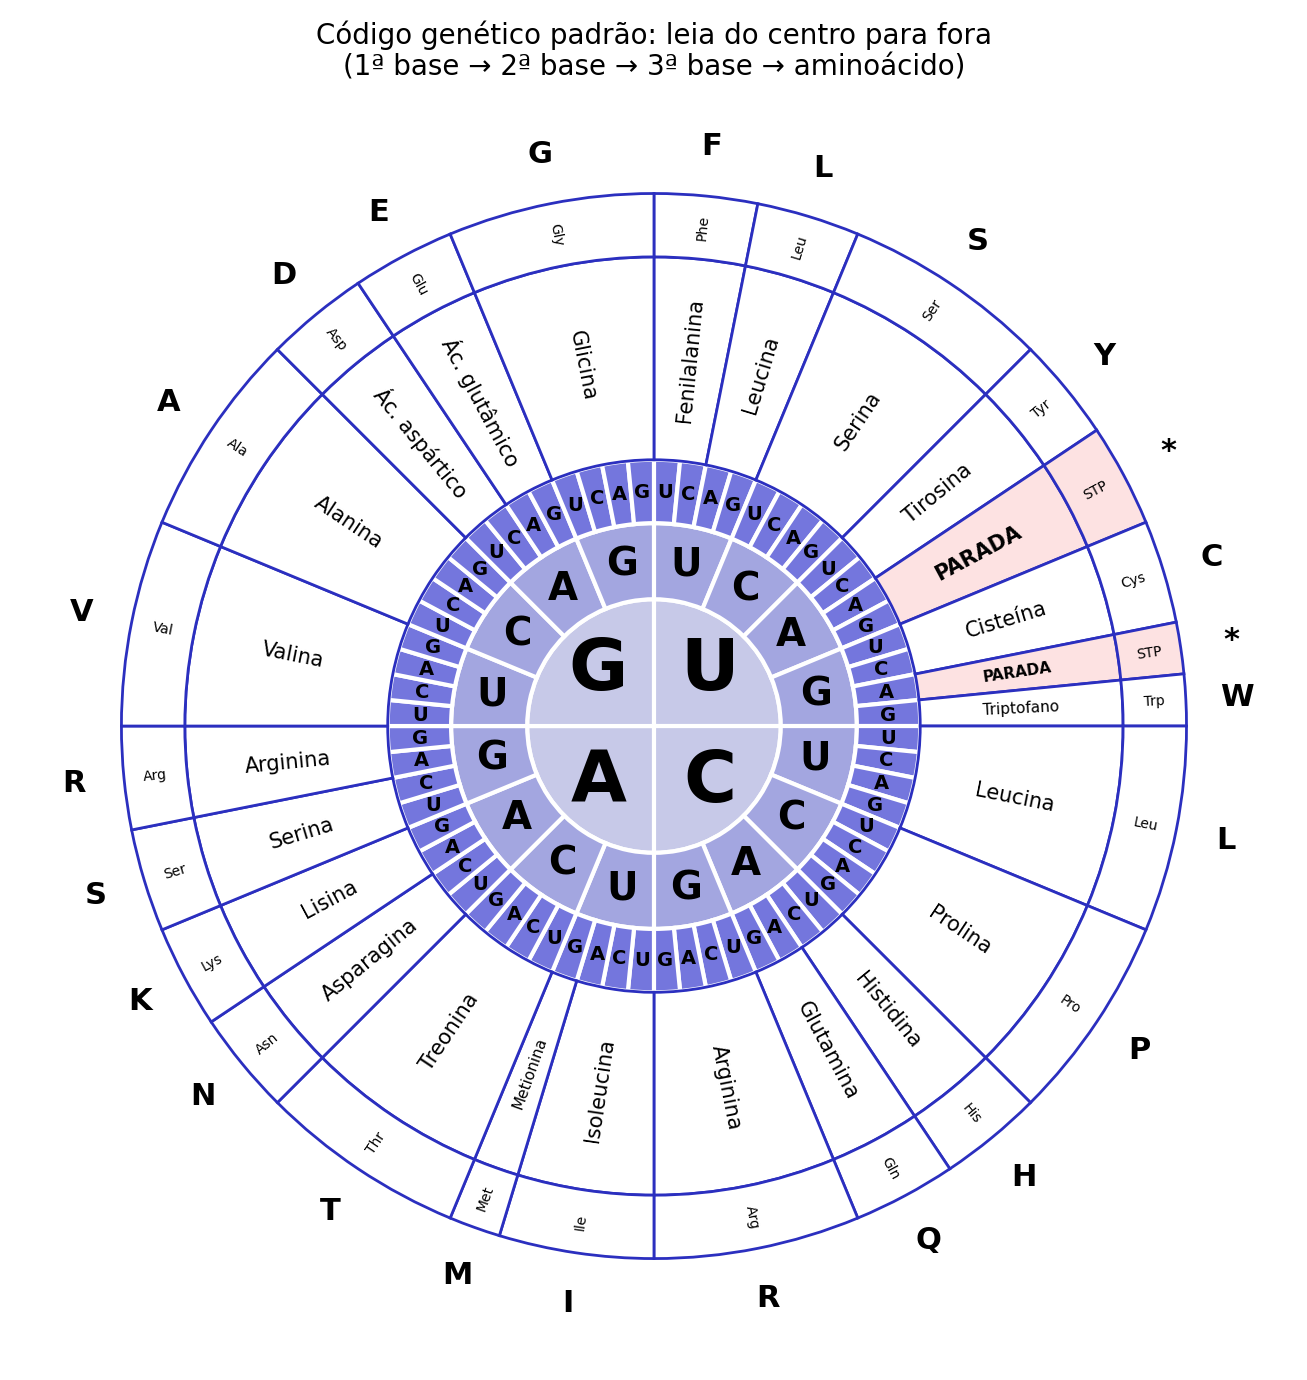

In [220]:
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "retina"
from matplotlib.patches import Wedge

# Código genético padrão (ordem U, C, A, G para cada posição do códon)
BASES = "UCAG"
AMINOACIDOS = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"

NOMES = {
    "F": ("Phe", "Fenilalanina"), "L": ("Leu", "Leucina"), "S": ("Ser", "Serina"),
    "Y": ("Tyr", "Tirosina"), "*": ("STP", "PARADA"), "C": ("Cys", "Cisteína"),
    "W": ("Trp", "Triptofano"), "P": ("Pro", "Prolina"), "H": ("His", "Histidina"),
    "Q": ("Gln", "Glutamina"), "R": ("Arg", "Arginina"), "I": ("Ile", "Isoleucina"),
    "M": ("Met", "Metionina"), "T": ("Thr", "Treonina"), "N": ("Asn", "Asparagina"),
    "K": ("Lys", "Lisina"), "V": ("Val", "Valina"), "A": ("Ala", "Alanina"),
    "D": ("Asp", "Ác. aspártico"), "E": ("Glu", "Ác. glutâmico"), "G": ("Gly", "Glicina"),
}

codons = [b1 + b2 + b3 for b1 in BASES for b2 in BASES for b3 in BASES]
codigo = dict(zip(codons, AMINOACIDOS))

# Raios dos anéis (de dentro para fora)
R_BASE1, R_BASE2, R_BASE3 = 1.0, 1.6, 2.1
R_NOME, R_ABREV, R_LETRA = 3.7, 4.2, 4.6

LARGURA = 360 / 64  # ângulo ocupado por cada códon


def angulos(inicio, n_codons):
    """Converte posição (em códons) em ângulos, girando no sentido horário a partir do topo."""
    theta2 = 90 - inicio * LARGURA
    theta1 = theta2 - n_codons * LARGURA
    return theta1, theta2


def texto_radial(eixo, angulo, raio, texto, **kwargs):
    """Escreve um texto alinhado ao raio, sempre legível (nunca de cabeça para baixo)."""
    x, y = raio * np.cos(np.radians(angulo)), raio * np.sin(np.radians(angulo))
    rotacao = angulo if np.cos(np.radians(angulo)) >= 0 else angulo + 180
    eixo.text(x, y, texto, rotation=rotacao, rotation_mode="anchor",
              ha="center", va="center", **kwargs)


def texto_reto(eixo, angulo, raio, texto, **kwargs):
    x, y = raio * np.cos(np.radians(angulo)), raio * np.sin(np.radians(angulo))
    eixo.text(x, y, texto, ha="center", va="center", **kwargs)


fig, eixo = plt.subplots(figsize=(7, 7))

# Anéis das três posições do códon
aneis = [(0, R_BASE1, 16, "#c7c9e8", 26), (R_BASE1, R_BASE2, 4, "#a3a6e0", 14),
         (R_BASE2, R_BASE3, 1, "#7476dd", 7)]

for r_int, r_ext, tamanho_bloco, cor, fonte in aneis:
    for i in range(0, 64, tamanho_bloco):
        t1, t2 = angulos(i, tamanho_bloco)
        eixo.add_patch(Wedge((0, 0), r_ext, t1, t2, width=r_ext - r_int,
                             facecolor=cor, edgecolor="white", linewidth=1.5))
        posicao = {16: 0, 4: 1, 1: 2}[tamanho_bloco]
        base = codons[i][posicao]
        raio_texto = (r_int + r_ext) / 2 if r_int > 0 else 0.62
        texto_reto(eixo, (t1 + t2) / 2, raio_texto, base, fontsize=fonte, fontweight="bold")

# Anéis dos aminoácidos: agrupa códons consecutivos que codificam o mesmo aminoácido
i = 0
while i < 64:
    letra = codigo[codons[i]]
    j = i
    while j < 64 and codigo[codons[j]] == letra:
        j += 1
    t1, t2 = angulos(i, j - i)
    meio = (t1 + t2) / 2
    abrev, nome = NOMES[letra]
    cor = "#fde2e2" if letra == "*" else "white"

    eixo.add_patch(Wedge((0, 0), R_NOME, t1, t2, width=R_NOME - R_BASE3,
                         facecolor=cor, edgecolor="#2b2fbf", linewidth=1))
    eixo.add_patch(Wedge((0, 0), R_ABREV, t1, t2, width=R_ABREV - R_NOME,
                         facecolor=cor, edgecolor="#2b2fbf", linewidth=1))

    tamanho = 7.5 if j - i > 1 else 5.5
    texto_radial(eixo, meio, (R_BASE3 + R_NOME) / 2, nome, fontsize=tamanho,
                 fontweight="bold" if letra == "*" else "normal")
    texto_radial(eixo, meio, (R_NOME + R_ABREV) / 2, abrev, fontsize=5)
    texto_reto(eixo, meio, R_LETRA, letra, fontsize=11, fontweight="bold")
    i = j

eixo.set_xlim(-5, 5)
eixo.set_ylim(-5, 5)
eixo.set_aspect("equal")
eixo.axis("off")
eixo.set_title("Código genético padrão: leia do centro para fora\n"
               "(1ª base → 2ª base → 3ª base → aminoácido)", fontsize=10)
plt.tight_layout()
plt.show()

<a id="metodologia"></a>
## 2. Metodologia

$ \ \ \ \ \ $ Para responder à pergunta deste trabalho, foi seguido o fluxo usual de um projeto de aprendizado de máquina, com cuidado especial para evitar o vazamento de dados, isto é, para que nenhuma informação do conjunto de teste influencie a construção ou a escolha dos modelos. As etapas foram as seguintes:

1. **Preparação dos dados:** limpeza do conjunto de dados e definição do *target* (grupo taxonômico) e dos atributos (frequências dos 64 códons e número total de códons).
2. **Divisão em treino e teste:** separação estratificada em 80% para treino e 20% para teste, preservando a proporção de cada classe. O conjunto de teste é guardado e usado apenas no final.
3. **Análise exploratória:** estudo do conjunto de treino para entender a distribuição das classes e os padrões de uso de códons em cada grupo taxonômico.
4. ***Baseline*:** indução de um modelo que sempre prevê a classe mais frequente, servindo como referência mínima de desempenho.
5. **Otimização de hiperparâmetros:** busca dos melhores hiperparâmetros para cada algoritmo com o Optuna.
6. **Comparação dos modelos:** comparação dos melhores modelos de cada algoritmo por validação cruzada.
7. **Avaliação final:** medida do desempenho do melhor modelo no conjunto de teste.
8. **Interpretação:** análise de quais códons mais influenciam as previsões e discussão dos resultados à luz da teoria, isto é, da Biologia.

$ \ \ \ \ \ $ Foram comparados cinco algoritmos de classificação, escolhidos por representarem estratégias diferentes de aprendizado: a **regressão logística**, um modelo linear; o ***k*-vizinhos mais próximos (*k*-NN)**, baseado nas distâncias entre os exemplos; a **árvore de decisão**, baseada em regras de divisão dos dados; e a **floresta aleatória** e o **[quinto algoritmo]**, modelos de comitê que combinam várias árvores de decisão.

$ \ \ \ \ \ $ Cada algoritmo foi inserido em um **pipeline**, uma sequência de etapas em que o pré-processamento dos dados (como a normalização e a redução de dimensionalidade) é seguido pelo modelo. A vantagem do pipeline é que todas as etapas são ajustadas apenas com os dados de treino de cada momento, o que impede que informações dos dados de validação ou de teste vazem para o modelo.

$ \ \ \ \ \ $ Os hiperparâmetros de cada pipeline foram otimizados com a biblioteca **Optuna** [[4]](#refs). Em vez de testar todas as combinações possíveis, o Optuna usa os resultados das tentativas anteriores para direcionar a busca para as regiões mais promissoras. Para cada algoritmo, foram testados 100 conjuntos de hiperparâmetros, e cada conjunto foi avaliado por **validação cruzada estratificada com 5 folds no conjunto de treino: os dados de treino são divididos em 5 partes, e o modelo é treinado em 4 e avaliado na restante, repetindo o processo até que todas as partes tenham sido usadas na avaliação. A média dessas 5 avaliações é uma estimativa de desempenho mais confiável do que uma única divisão dos dados.

$ \ \ \ \ \ $ Como as classes são desbalanceadas, a métrica utilizada foi a **[F1 macro]**, que calcula o F1 de cada classe separadamente e faz a média simples entre elas, dando o mesmo peso a todas as classes. Assim, um modelo só obtém um bom resultado se acertar bem todos os grupos taxonômicos, e não apenas os mais frequentes.

$ \ \ \ \ \ $ Ao final, o pipeline com melhor desempenho na validação cruzada foi treinado com todo o conjunto de treino e avaliado uma única vez no conjunto de teste. Todas as análises foram realizadas em Python, com as bibliotecas pandas, NumPy, Matplotlib, Seaborn, scikit-learn e Optuna que serão importadas na seção [[3.1]](#pre).

<a id="desenvolvimento"></a>
## 3. Desenvolvimento

<a id="pre"></a>
### 3.1 Preparação do Ambiente Inicial

$ \ \ \ \ \ $ Para o desenvolvimento deste trabalho, foram importadas diversas bibliotecas da linguagem Python (3.13.7).

In [261]:
# Utilidades
import os
import zipfile
import warnings

# Manipulação de dados e gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Otimização de hiperparâmetros
import optuna
from functools import partial
from optuna import create_study
from optuna.samplers import TPESampler
import optuna.visualization.matplotlib as vis

# scikit-learn: divisão dos dados e validação cruzada
import sklearn
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    cross_val_score,
)

# scikit-learn: pré-processamento e pipeline
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif

# scikit-learn: modelos
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# scikit-learn: avaliação e explicabilidade
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
)
from sklearn.inspection import permutation_importance

# Constantes do projeto
SEMENTE_ALEATORIA = 140             # semente para reprodutibilidade
TAMANHO_TESTE = 0.2    # 20% dos dados reservados para o teste final
NUM_TENTATIVAS = 100         # conjuntos de hiperparâmetros por algoritmo
NUM_FOLDS = 5            # folds da validação cruzada
METRICA = "f1_macro"   # métrica principal (pode mudar depois)

# Configurações
optuna.logging.set_verbosity(optuna.logging.WARNING)  # deixa a saída do Optuna mais limpa
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | optuna {optuna.__version__}")

pandas 2.3.3 | scikit-learn 1.7.2 | optuna 4.5.0


<a id="carr"></a>
### 3.2 Carregamento, Limpeza e Escolha do Target 

#### 3.2.1 Convertendo o DataSet em um DataFrame

$ \ \ \ \ \ $ Inicialmente, para carregar os dados baixamos o DataSet "Codon Usage" disponibilizado no UCI Machine Learning Repository [[2]](#refs) e subimos o arquivo na mesma pasta deste Jupyter Notebook. Assim, foi possível converter um arquivo .csv em um dataframe - estrutura de dados tabulados - que pode ser manipulado utilizando a biblioteca `pandas`. O DataFrame em questão possui 13.028 exemplos (linhas) que são os organismos contemplados e 69 atributos, também chamados de features (colunas) que englobam o tipo de DNA, o número e a frequência dos códons. 

In [222]:
CAMINHO_DADOS = "codon_usage.csv"  

df = pd.read_csv(CAMINHO_DADOS, low_memory=False)
print(df.shape)
df.head()

(13028, 69)


,Kingdom,DNAtype,SpeciesID,Ncodons,SpeciesName,UUU,UUC,UUA,UUG,CUU,...,CGG,AGA,AGG,GAU,GAC,GAA,GAG,UAA,UAG,UGA
0,vrl,0,100217,1995,Epizootic haematopoietic necrosis virus,0.01654,0.01203,0.00050,0.00351,0.01203,...,0.00451,0.01303,0.03559,0.01003,0.04612,0.01203,0.04361,0.00251,0.00050,0.00000
1,vrl,0,100220,1474,Bohle iridovirus,0.02714,0.01357,0.00068,0.00678,0.00407,...,0.00136,0.01696,0.03596,0.01221,0.04545,0.01560,0.04410,0.00271,0.00068,0.00000
2,vrl,0,100755,4862,Sweet potato leaf curl virus,0.01974,0.0218,0.01357,0.01543,0.00782,...,0.00596,0.01974,0.02489,0.03126,0.02036,0.02242,0.02468,0.00391,0.00000,0.00144
3,vrl,0,100880,1915,Northern cereal mosaic virus,0.01775,0.02245,0.01619,0.00992,0.01567,...,0.00366,0.01410,0.01671,0.03760,0.01932,0.03029,0.03446,0.00261,0.00157,0.00000
4,vrl,0,100887,22831,Soil-borne cereal mosaic virus,0.02816,0.01371,0.00767,0.03679,0.01380,...,0.00604,0.01494,0.01734,0.04148,0.02483,0.03359,0.03679,0.00000,0.00044,0.00131


#### 3.2.2 Correção dos tipos das colunas dos códons 

$ \ \ \ \ \ $ Como os modelos de aprendizado de máquina só trabalham com dados numéricos, verificamos o tipo de dado das 64 colunas de frequência de códons, que estão a partir da sexta coluna do `DataFrame`. Das 64 colunas, 62 são do tipo `float64` (números decimais), como esperado para frequências. No entanto, 2 colunas foram lidas como `object` (texto), o que indica que algumas linhas contêm valores não numéricos nessas colunas.

In [223]:
colunas_codons = df.columns[5:].tolist()
print("Número de colunas de códons:", len(colunas_codons))
print(df[colunas_codons].dtypes.value_counts())

Número de colunas de códons: 64
float64    62
object      2
Name: count, dtype: int64


$ \ \ \ \ \ $ Para corrigir esse problema, todas as colunas de códons foram convertidas para o tipo numérico com a função `pd.to_numeric`. O argumento `errors="coerce"` faz com que os valores que não podem ser convertidos em números sejam substituídos por `NaN` (valor ausente), em vez de interromper o código com um erro.

In [224]:
colunas_texto = df[colunas_codons].select_dtypes(include="object").columns.tolist()
print("Colunas lidas como texto:", colunas_texto)

df[colunas_codons] = df[colunas_codons].apply(pd.to_numeric, errors="coerce")

linhas_problema = df[df[colunas_codons].isna().any(axis=1)]
print("Linhas com valores não numéricos:", len(linhas_problema))
linhas_problema.iloc[:, :7]

Colunas lidas como texto: ['UUU', 'UUC']
Linhas com valores não numéricos: 2


,Kingdom,DNAtype,SpeciesID,Ncodons,SpeciesName,UUU,UUC
486,vrl,0,12440,1238,Non-A,NaN,0.04362
5063,bct,0,353569,1698,Salmonella enterica subsp. enterica serovar 4,NaN,NaN


$ \ \ \ \ \ $ As colunas lidas como texto foram [`UUU` e `UUC`]. Em seguida, identificamos as linhas que passaram a ter valores ausentes após a conversão. Foram encontradas 2 linhas com valores não numéricos, que correspondem a entradas mal formatadas no arquivo original. Como essas linhas representam uma parcela muito pequena do conjunto de dados e não é possível recuperar os valores corretos, elas foram removidas. Após a remoção, o `DataFrame` passou a ter 13026 linhas.

In [225]:
df = df.dropna(subset=colunas_codons).reset_index(drop=True)
print(df.shape)

(13026, 69)


#### 3.2.3 Soma das frequências 

$ \ \ \ \ \ $ Como cada frequência corresponde à proporção de um códon em relação ao total de códons do organismo, a soma das 64 frequências de cada organismo deve ser igual a 1. Para verificar a integridade dos dados após a conversão para valores numéricos, calculamos essa soma para cada linha do DataFrame.

In [226]:
soma_frequencias = df[colunas_codons].sum(axis=1)
soma_frequencias.describe()

count    13026.000000
mean         0.999999
std          0.000031
min          0.999840
25%          0.999980
50%          1.000000
75%          1.000020
max          1.000170
dtype: float64

$ \ \ \ \ \ $ As somas variaram entre 0,99984 e 1,00017, com média praticamente igual a 1 e desvio padrão de 0,00003. As pequenas diferenças se devem ao arredondamento das frequências, registradas com 5 casas decimais: como cada valor pode ter um erro de até 0,000005, a soma das 64 frequências pode diferir de 1 em até 0,00032. Assim, os dados estão consistentes. Essa verificação também revela uma característica importante dos atributos: como as frequências sempre somam 1, qualquer uma delas pode ser obtida a partir das outras 63, ou seja, os atributos são redundantes entre si. Essa característica será retomada na etapa de pré-processamento, uma vez que como temos atributos redundantes, os dados são multicolinearmente perfeitos, justificando o uso de PCA posteriormente.

#### 3.2.4 Organismos com Poucos Códons

$ \ \ \ \ \ $ Quando o número total de códons (`Ncodons`) é pequeno, as estimativas de frequência ficam pouco confiáveis, pois muitos códons podem aparecer poucas vezes ou nenhuma apenas por acaso. Por isso, o autor do conjunto de dados descartou, previamente, os organismos com menos de 1000 códons. Para verificar se esse critério de fato condiz com os dados que temos, disponibilizados no UCI: o menor valor de `Ncodons` é 1000, e nenhum organismo possui um valor menor que esse. Assim, nenhum organismo precisou ser removido nesta etapa. Limites mais altos não foram adotados, pois eliminariam grande parte do conjunto de dados: com um limite de 3000 códons, por exemplo, seriam removidos 6.628 organismos, mais da metade do total, e aumentando esse limite mais organismos seriam eliminados sem necessidade prática.

In [227]:
for limite in [1000, 3000, 5000, 10000]:
    print(f"Ncodons < {limite}: {(df['Ncodons'] < limite).sum()} organismos")

Ncodons < 1000: 0 organismos
Ncodons < 3000: 6628 organismos
Ncodons < 5000: 8479 organismos
Ncodons < 10000: 9957 organismos


In [228]:
MIN_CODONS = 1001

print("Menor número de códons:", df["Ncodons"].min())
print(f"Organismos com menos de {MIN_CODONS} códons:", (df["Ncodons"] < MIN_CODONS).sum())

Menor número de códons: 1000
Organismos com menos de 1001 códons: 10


#### 3.2.5 Espécies Duplicadas

$ \ \ \ \ \ $ Nesta etapa, verificamos se há organismos repetidos no conjunto de dados, já que exemplos duplicados podem cair tanto no treino quanto no teste e superestimar o desempenho dos modelos, o que constitui-se como um tipo de vazamento de dados.

In [229]:
print("SpeciesID repetidos:", df["SpeciesID"].duplicated().sum())
print("Linhas com frequências idênticas:", df.duplicated(subset=colunas_codons).sum())

SpeciesID repetidos: 660
Linhas com frequências idênticas: 40


$ \ \ \ \ \ $ Usando o método `duplicated()` foram encontradas 40 linhas com frequências de códons idênticas. Como essas linhas são cópias exatas umas das outras, elas foram removidas, restando 12.986 organismos.

$ \ \ \ \ \ $ Também foram encontrados 660 valores repetidos de `SpeciesID`, mas essas linhas não foram removidas, pois a mesma espécie pode ter mais de um tipo de DNA. Um mesmo organismo pode ter uma entrada para o genoma nuclear e outra para o genoma mitocondrial ou de cloroplasto. Esses genomas têm frequências de códons diferentes e, portanto, não são duplicatas. O `SpeciesID` não é único no conjunto de dados inteiro. Ele identifica a espécie apenas dentro do arquivo de cada reino no banco de dados CUTG. Assim, o mesmo número pode corresponder a espécies diferentes em reinos diferentes.

In [230]:
df = df.drop_duplicates(subset=colunas_codons).reset_index(drop=True)
print(df.shape)

(12986, 69)


$ \ \ \ \ \ $ O conjunto de dados contém entradas de diferentes tipos de DNA: além do DNA genômico (nuclear), há entradas de DNA de organelas, como mitocôndrias e cloroplastos, indicadas pela coluna `DNAtype`. Para entender como esses tipos de DNA se distribuem entre os grupos taxonômicos, construímos uma tabela de contingência com a função `pd.crosstab` do `pandas`. Essa função cruza duas colunas e conta quantas linhas existem para cada combinação de valores. Nesta tabela, cada linha corresponde a um grupo taxonômico (`Kingdom`), cada coluna a um tipo de DNA (`DNAtype`), e cada célula indica quantos organismos daquele grupo possuem aquele tipo de DNA.

$ \ \ \ \ \ $ Como já mencionado na Tabela 1 na [Introdução](#intro), os códigos de `DNAtype` correspondem a: 0 (genômico), 1 (mitocondrial), 2 (cloroplasto), 3 (cianela), 4 (plastídio), 5 (nucleomorfo), 6 (endossimbionte secundário), 7 (cromoplasto), 8 (leucoplasto), 9 (não disponível), 10 (proplastídio), 11 (apicoplasto) e 12 (cinetoplasto).

In [231]:
tabela_porcentagem = pd.crosstab(df["Kingdom"], df["DNAtype"], normalize="index") * 100
tabela_porcentagem.round(1)

DNAtype,0,1,2,3,4,5,6,7,9,11,12
Kingdom,,,,,,,,,,,
arc,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
bct,99.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
inv,68.6,30.5,0.1,0.0,0.2,0.1,0.0,0.0,0.0,0.1,0.4
mam,17.8,82.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phg,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
plm,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
pln,60.7,6.1,31.9,0.1,1.1,0.0,0.0,0.0,0.1,0.0,0.0
pri,46.1,53.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
rod,27.4,72.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


$ \ \ \ \ \ $ A tabela mostra uma forte relação entre o tipo de DNA e o grupo taxonômico. Arqueias, bacteriófagos, plasmídeos e vírus possuem apenas entradas de DNA genômico (`DNAtype` igual a 0), e as bactérias possuem apenas duas entradas de outros tipos entre 2.908. Isso é esperado, pois esses organismos não possuem organelas como mitocôndrias e cloroplastos.

$ \ \ \ \ \ $ Entre os vertebrados, a situação é oposta, pois as entradas de DNA mitocondrial (`DNAtype` igual a 1) são a maioria em todos os grupos, correspondendo a cerca de 82% das entradas de mamíferos, aproximadamente 78% dos demais vertebrados, cerca de 73% dos roedores e 54% dos primatas. Nas plantas, o DNA genômico corresponde a cerca de 61% das entradas, seguido pelo DNA de cloroplasto, com aproximadamente 32%, e pelo DNA mitocondrial, com cerca de 6%. As plantas são praticamente o único grupo com DNA de cloroplasto. Nos invertebrados, cerca de 31% das entradas são de DNA mitocondrial, e menos de 1% correspondem a organelas raras, como apicoplasto e cinetoplasto, encontradas em protistas parasitas. Os demais tipos de DNA possuem pouquíssimas entradas, e os tipos 8 (leucoplasto) e 10 (proplastídio) não aparecem no conjunto de dados.

$ \ \ \ \ \ $ Essa relação poderia comprometer o trabalho, pois se as entradas de organelas fossem mantidas, os modelos poderiam aprender atalhos como "DNA de cloroplasto indica planta" ou "DNA mitocondrial indica vertebrado", em vez de aprender o padrão de uso de códons de cada grupo. Além disso, as mitocôndrias utilizam variações do código genético padrão, de modo que seu uso de códons difere bastante do DNA nuclear do mesmo organismo. Por esses motivos, foram mantidas apenas as entradas de DNA genômico. Com isso, a coluna `DNAtype` passa a ter o mesmo valor em todas as linhas e deixa de ser utilizada como atributo.

In [232]:
df = df[df["DNAtype"] == 0].reset_index(drop=True)
print(df.shape)

(9240, 69)


$ \ \ \ \ \ $ Após essa seleção, restaram 9.240 organismos. 

$ \ \ \ \ \ $ Por fim, uma última limpeza no DataSet diz respeito às espécies repetidas. Na etapa de remoção de duplicatas, foram eliminadas apenas as linhas com frequências de códons exatamente iguais. No entanto, organismos muito semelhantes, como diferentes cepas de uma mesma bactéria, podem ter frequências ligeiramente diferentes e, por isso, não ser detectados como duplicatas. Se esses organismos ficassem divididos entre os conjuntos de treino e de teste, o modelo teria acesso, durante o treino, a exemplos quase idênticos aos do teste, o que superestimaria seu desempenho - tipo de vazamento de dado apresentado no Notebook Jupyter do Prof. Dr. Daniel Roberto Cassar "Vazamento de Dados" [[4]](#refs).  Como o `SpeciesID` não identifica as espécies de forma única no conjunto de dados, essa verificação foi feita pelo nome da espécie (`SpeciesName`), agora que restaram apenas as entradas de DNA genômico.

In [233]:
print("Nomes de espécie repetidos:", df["SpeciesName"].duplicated().sum())
df[df["SpeciesName"].duplicated(keep=False)].sort_values("SpeciesName").iloc[:, :6]

Nomes de espécie repetidos: 12


,Kingdom,DNAtype,SpeciesID,Ncodons,SpeciesName,UUU
2368,vrl,0,437060,1105,Ageratum yellow vein Hualian virus-[Taiwan,0.01538
2369,vrl,0,437061,1106,Ageratum yellow vein Hualian virus-[Taiwan,0.01447
2370,vrl,0,437062,1106,Ageratum yellow vein Hualian virus-[Taiwan,0.01447
2019,vrl,0,369954,1158,Cotton leaf curl Rajasthan virus - [India,0.01813
2020,vrl,0,369955,1140,Cotton leaf curl Rajasthan virus - [India,0.01754
2021,vrl,0,369956,1138,Cotton leaf curl Rajasthan virus - [India,0.01582
5155,bct,0,373045,1222,Escherichia coli O111,0.05155
3874,bct,0,168927,2086,Escherichia coli O111,0.01007
5283,bct,0,397453,1417,Escherichia coli O111,0.00988
5233,bct,0,386585,1639585,Escherichia coli O157,0.02215


In [234]:
df = df.drop_duplicates(subset="SpeciesName", keep="first").reset_index(drop=True)
print(df.shape)

(9228, 69)


#### 3.2.6 Definição do Target

$ \ \ \ \ \ $ Com todas as etapas de limpeza realizadas, garantindo a qualidade dos dados e evitando o vazamento de dados por exemplos repetidos, podemos definir o Target, isto é o resultado que um modelo supervisionado retorna de acordo com os atributos fornecidos.  Neste trabalho, o *target* é o grupo taxonômico do organismo, informado na coluna `Kingdom`. 

In [235]:
df["Kingdom"].value_counts()

Kingdom
bct    2901
vrl    2813
pln    1522
inv     922
vrt     464
phg     218
arc     126
mam     102
pri      83
rod      59
plm      18
Name: count, dtype: int64

$ \ \ \ \ \ $  Apesar do nome, a coluna `Kingdom` não corresponde aos reinos da classificação biológica formal: ela reproduz as divisões do banco de dados CUTG, que seguem a organização do GenBank. Por isso, algumas categorias não são reinos (como vírus e bacteriófagos) e outras estão contidas umas nas outras: roedores e primatas são mamíferos, e todos são vertebrados, enquanto a categoria `vrt` reúne os demais vertebrados. Além disso, após a limpeza, algumas dessas categorias ficaram com poucos exemplos, como os roedores (59 organismos) e os primatas (83 organismos), o que tornaria a avaliação dos modelos pouco confiável para essas classes.

$ \ \ \ \ \ $ Por esses motivos, as categorias foram reorganizadas em seis grupos taxonômicos: arqueias, bactérias, vírus (incluindo os bacteriófagos, que são vírus que infectam bactérias), plantas, invertebrados e vertebrados (reunindo mamíferos, roedores, primatas e os demais vertebrados). Optamos por excluir os s plasmídeos, pois não são organismos, mas moléculas de DNA presentes no interior de bactérias, além de possuírem apenas 18 exemplos. Para facilitar a leitura dos resultados, os códigos de três letras foram substituídos pelos nomes dos grupos em português, armazenados na coluna `Grupo`, que, como já mencionado, será utilizada como target.

In [236]:
NOMES_GRUPOS = {
    "arc": "Arqueias",
    "bct": "Bactérias",
    "phg": "Vírus",         
    "vrl": "Vírus",
    "pln": "Plantas",
    "inv": "Invertebrados",
    "vrt": "Vertebrados",
    "mam": "Vertebrados",
    "rod": "Vertebrados",
    "pri": "Vertebrados",
}

logica = df["Kingdom"] != "plm"
df = df.loc[logica].reset_index(drop=True)

df["Grupo"] = df["Kingdom"].map(NOMES_GRUPOS)

df["Grupo"].value_counts()

Grupo
Vírus            3031
Bactérias        2901
Plantas          1522
Invertebrados     922
Vertebrados       708
Arqueias          126
Name: count, dtype: int64

$ \ \ \ \ \ $ A fim de demonstrar o quão desbalanceados os dados estão, o que influencia modelos como o Baseline, que prevê como resultado a categoria mais frequente, foi plotado um gráfico que apresenta a Distribuição dos organismos entre os grupos taxonômicos já citados.

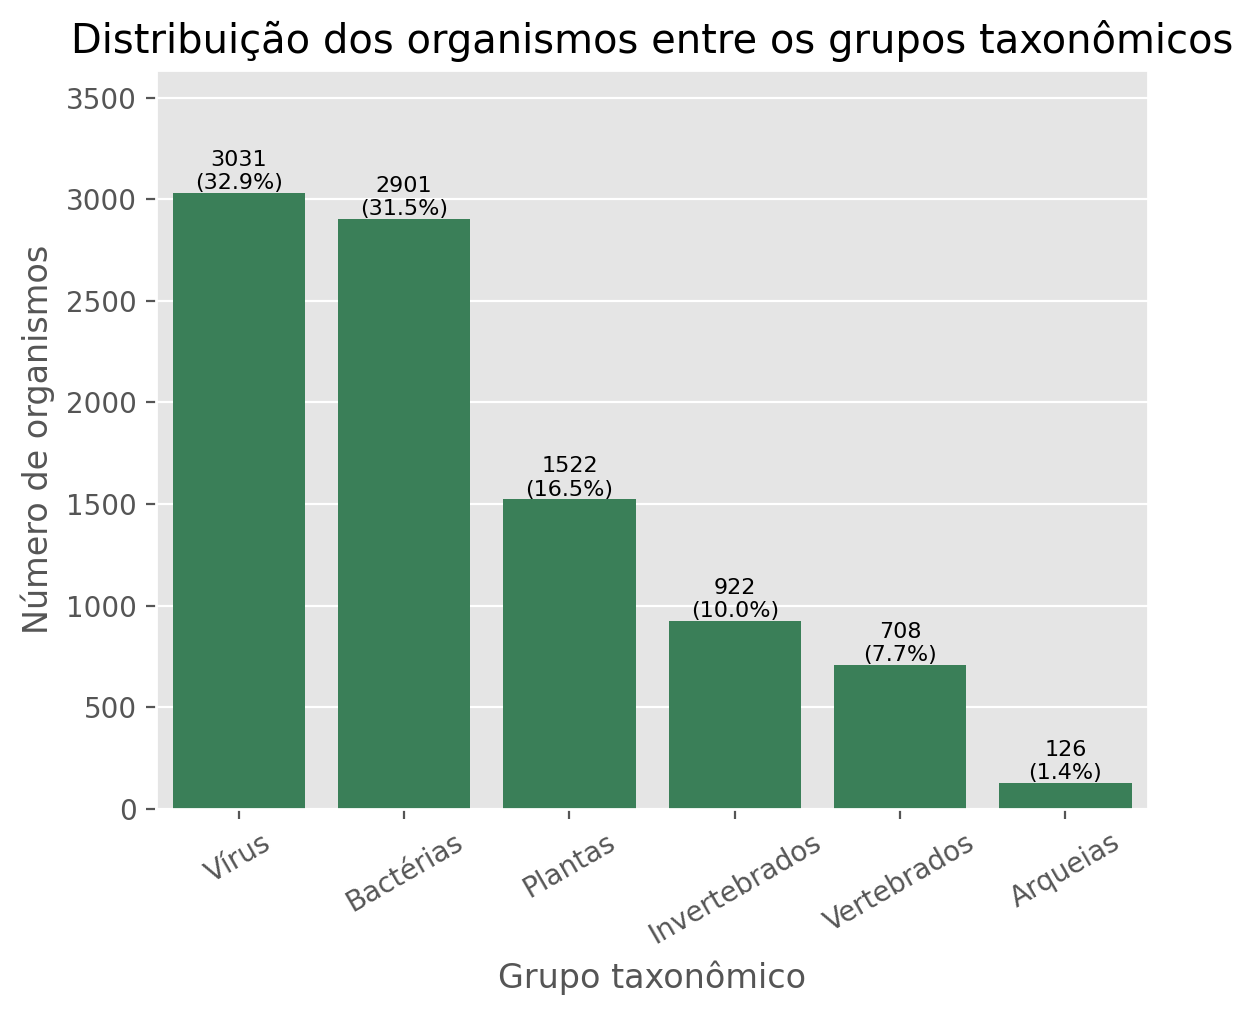

In [237]:
contagem = df["Grupo"].value_counts()
porcentagem = contagem / contagem.sum() * 100

eixo = sns.barplot(x=contagem.index, y=contagem.values, color = "seagreen")
eixo.bar_label(
    eixo.containers[0],
    labels=[f"{n}\n({p:.1f}%)" for n, p in zip(contagem.values, porcentagem.values)],
    fontsize=8,
)
eixo.set(
    xlabel="Grupo taxonômico",
    ylabel="Número de organismos",
    title="Distribuição dos organismos entre os grupos taxonômicos",
)
eixo.set_ylim(0, contagem.max() * 1.2)
plt.xticks(rotation=30);

discussão!!

$ \ \ \ \ \ $ Definimos, por fim, quais colunas serão utilizadas como atributos e qual será o target. Os atributos são as frequências dos 64 códons e o número total de códons (`Ncodons`), totalizando 65 atributos. O *target* é o grupo taxonômico (`Grupo`). Relembrando que as colunas `SpeciesID` e `SpeciesName` não foram utilizadas, por serem apenas identificadores dos organismos, assim como a coluna `DNAtype`, que passou a ter o mesmo valor em todas as linhas após a seleção do DNA genômico.

In [238]:
ATRIBUTOS = colunas_codons + ["Ncodons"]
TARGET = ["Grupo"]

print("Número de organismos (linhas):", len(df))
print("Número de atributos:", len(ATRIBUTOS))
print("Atributos:", ATRIBUTOS)
print()
print("Target:", TARGET[0])
print("Classes do target:", df["Grupo"].unique().tolist())

Número de organismos (linhas): 9210
Número de atributos: 65
Atributos: ['UUU', 'UUC', 'UUA', 'UUG', 'CUU', 'CUC', 'CUA', 'CUG', 'AUU', 'AUC', 'AUA', 'AUG', 'GUU', 'GUC', 'GUA', 'GUG', 'GCU', 'GCC', 'GCA', 'GCG', 'CCU', 'CCC', 'CCA', 'CCG', 'UGG', 'GGU', 'GGC', 'GGA', 'GGG', 'UCU', 'UCC', 'UCA', 'UCG', 'AGU', 'AGC', 'ACU', 'ACC', 'ACA', 'ACG', 'UAU', 'UAC', 'CAA', 'CAG', 'AAU', 'AAC', 'UGU', 'UGC', 'CAU', 'CAC', 'AAA', 'AAG', 'CGU', 'CGC', 'CGA', 'CGG', 'AGA', 'AGG', 'GAU', 'GAC', 'GAA', 'GAG', 'UAA', 'UAG', 'UGA', 'Ncodons']

Target: Grupo
Classes do target: ['Vírus', 'Arqueias', 'Bactérias', 'Plantas', 'Invertebrados', 'Vertebrados']


<a id="sep"></a>
### 3.3 Separação dos Dados de Treino e Teste

$ \ \ \ \ \ $ Para avaliar o desempenho de um modelo de forma honesta, sem sobreajustá-lo, é necessário medi-lo em dados que não foram utilizados durante o seu treino. Caso contrário, o modelo poderia simplesmente ter memorizado os exemplos e aparentar um desempenho melhor do que o real. Por isso, seguindo a estratégia apresentada no Material Não Publicado do Prof. Dr. Daniel Roberto Cassar [[X]](#refs), os dados foram divididos em um conjunto de treino, utilizado para treinar e escolher os modelos, e um conjunto de teste, reservado para medir o desempenho do modelo escolhido uma única vez, ao final do trabalho.

$ \ \ \ \ \ $ Separamos 80% dos organismos ao conjunto de treino e 20% ao conjunto de teste. Como as classes são desbalanceadas, a divisão foi feita de forma estratificada, através do `stratify=df["Grupo"]`, isto é, preservando a proporção de cada grupo taxonômico nos dois conjuntos. Sem a estratificação, um grupo pouco numeroso, como o das arqueias, poderia ficar concentrado em apenas um dos conjuntos por acaso. Além disso, a semente aleatória, atribuída na [Preparação do Ambiente Inicial](#pre) foi fixada para que a divisão seja sempre a mesma a cada execução do notebook.

In [239]:
indices = df.index
indices_treino, indices_teste = train_test_split(
    indices,
    test_size=TAMANHO_TESTE,
    random_state=SEMENTE_ALEATORIA,
    stratify=df["Grupo"],
)

df_treino = df.loc[indices_treino]
df_teste = df.loc[indices_teste]

print("Treino:", df_treino.shape)
print("Teste:", df_teste.shape)

Treino: (7368, 70)
Teste: (1842, 70)


$ \ \ \ \ \ $ Dos 9.210 organismos, 7.368 foram destinados ao conjunto de treino e 1.842 ao conjunto de teste. Em seguida, separamos em cada conjunto os atributos (`X`) e o *target* (`y`), utilizando as listas `ATRIBUTOS` e `TARGET` definidas anteriormente.

In [240]:
X_treino = df_treino.reindex(ATRIBUTOS, axis=1)
y_treino = df_treino.reindex(TARGET, axis=1).values.ravel()

X_teste = df_teste.reindex(ATRIBUTOS, axis=1)
y_teste = df_teste.reindex(TARGET, axis=1).values.ravel()

print("X_treino:", X_treino.shape, "| y_treino:", y_treino.shape)
print("X_teste:", X_teste.shape, "| y_teste:", y_teste.shape)

X_treino: (7368, 65) | y_treino: (7368,)
X_teste: (1842, 65) | y_teste: (1842,)


In [241]:
proporcoes = pd.DataFrame({
    "Treino (%)": df_treino["Grupo"].value_counts(normalize=True) * 100,
    "Teste (%)": df_teste["Grupo"].value_counts(normalize=True) * 100,
})
proporcoes.round(1)

,Treino (%),Teste (%)
Grupo,,
Vírus,32.9,32.9
Bactérias,31.5,31.5
Plantas,16.5,16.5
Invertebrados,10.0,10.0
Vertebrados,7.7,7.7
Arqueias,1.4,1.4


$ \ \ \ \ \ $ A tabela confirma que a estratificação preservou a proporção de cada grupo taxonômico nos conjuntos de treino e de teste. A partir deste ponto, todas as análises e decisões de modelagem são realizadas apenas com o conjunto de treino. Vale destacar que a divisão foi feita por organismo, de modo que espécies aparentadas, como as de um mesmo gênero, podem estar presentes tanto no conjunto de treino quanto no de teste. As implicações dessa escolha para a interpretação do desempenho dos modelos serão discutidas na seção [3.9](#interp).

$ \ \ \ \ \ $ Além disso, dentro do conjunto de treino, a escolha dos hiperparâmetros e a comparação entre os modelos serão feitas por validação cruzada.

<a id="exp"></a>
### 3.4 Análise Exploratória

#### 3.4.1 Número de Códons por Grupo Taxonômico

$ \ \ \ \ \ $ Objetivando compreender melhor o conjunto de dados que trabalharemos, vamos utilizar algumas estratégias de análise exploratória, como uma visualização gráfica através de boxplots, possível graças à biblioteca `seaborn`. Esse gráfico mostra como o número total de códons (Ncodons) varia dentro de cada grupo taxonômico. Cada caixa corresponde a um grupo, e o eixo vertical mostra quantos códons foram contabilizados para cada organismo.

$ \ \ \ \ \ $ O Ncodons, biologicamente, indica nos fornece duas informações. Além de estar relacionada ao tamanho do genoma, por exemplo vírus tem genomas pequenos, com poucos genes, então tendem a ter poucos códons, o número de códons está relacionado com o quanto aquela espécie foi estudada. Um organismo modelo como é o caso da E. coli ou o ser humano que é extremamente pesquisado têm consideravelmente mais genes sequenciados do que uma espécie pouco conhecida. 

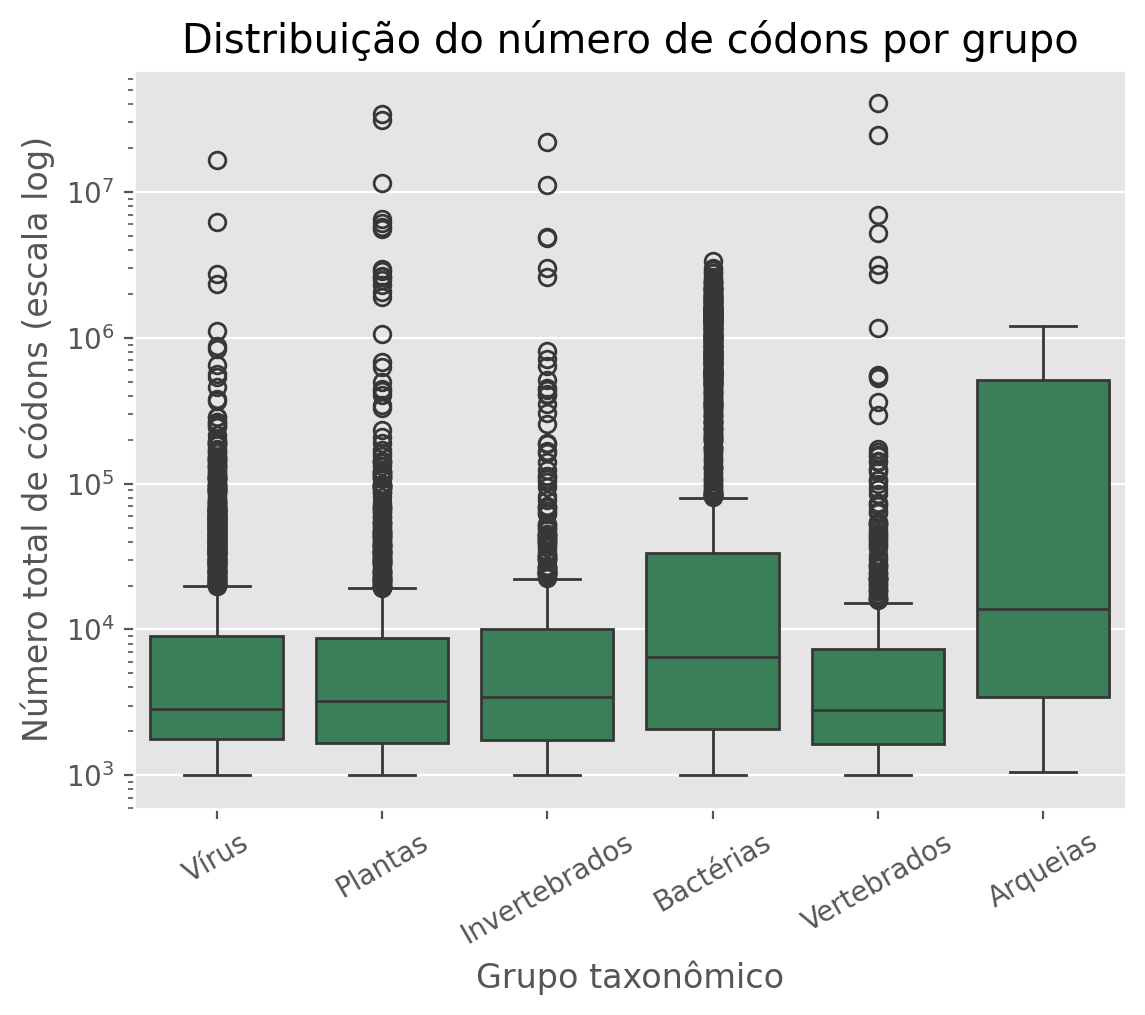

In [242]:
eixo = sns.boxplot(data=df_treino, x="Grupo", y="Ncodons", color="seagreen")
eixo.set_yscale("log")
eixo.set(
    xlabel="Grupo taxonômico",
    ylabel="Número total de códons (escala log)",
    title="Distribuição do número de códons por grupo",
)
plt.xticks(rotation=30);

$ \ \ \ \ \ $ Analisando os boxplots, é perceptível que todos têm como valor mínimo 1000 códons como já comprovado na seção de [Carregamento, Limpeza e Escolha do Target](#carr) Além disso, é evidente como quatro grupos taxonômicos têm distribuições muito parecidas. Vírus, plantas, invertebrados e vertebrados têm medianas próximas de 3.000 códons. Isso, embora possa parecer surpreendente, uma vez que os genomas de plantas e vertebrados são muito maiores que os de vírus, está relacionado com fato, já mencionado, de o Ncodons não medir o tamanho do genoma em si, mas quantas sequências codificantes da espécie estavam no GenBank. Dessa forma, para a maioria das plantas e dos animais, só alguns genes tinham sido sequenciados, e por isso eles têm tão poucos códons quanto um vírus.

$ \ \ \ \ \ $ Bactérias e arqueias apresentam valores mais altos, com medianas de cerca de 6.500 e 14.000 códons, respectivamente, e uma grande quantidade de organismos com centenas de milhares a milhões de códons. Isso é coerente com o fato de que muitos procariontes tiveram seus genomas completamente sequenciados, por serem pequenos e mais fáceis de sequenciar. Já os valores extremos observados entre os eucariontes, de dezenas de milhões de códons, provavelmente correspondem a organismos modelo, amplamente estudados.

$ \ \ \ \ \ $ Como as distribuições dos grupos se sobrepõem bastante, o `Ncodons` sozinho não é suficiente para distinguir os grupos taxonômicos, o que reforça a importância das frequências de códons para a classificação, e permite a análise objetivada pelo trabalho. 

$ \ \ \ \ \ $ Como optamos por utilizar a escala logarítmica no gráfico, pois Ncodons vai de 1.000 a dezenas de milhões, e, portanto, em uma escala comum, os grupos com poucos códons ficariam espremidos no fundo do gráfico e seria impossível compará-los, também iremos realizar essa transformação nos dados, tanto de treino quanto de teste.

In [243]:
X_treino = X_treino.assign(Ncodons=np.log10(X_treino["Ncodons"]))
X_teste = X_teste.assign(Ncodons=np.log10(X_teste["Ncodons"]))

X_treino["Ncodons"].describe()

count    7368.000000
mean        3.809441
std         0.781163
min         3.000000
25%         3.253822
50%         3.549064
75%         4.115527
max         7.609195
Name: Ncodons, dtype: float64

#### 3.4.2 Perfil do Uso de Códons por Grupo Taxonômico

$ \ \ \ \ \ $ Para comparar os padrões de uso de códons entre os grupos taxonômicos, calculamos a frequência média de cada códon dentro de cada grupo, utilizando apenas o conjunto de treino. O mapa de cores apresenta essas médias: cada linha corresponde a um grupo, cada coluna a um códon, e as cores variam do roxo (frequências baixas) ao amarelo (frequências altas).

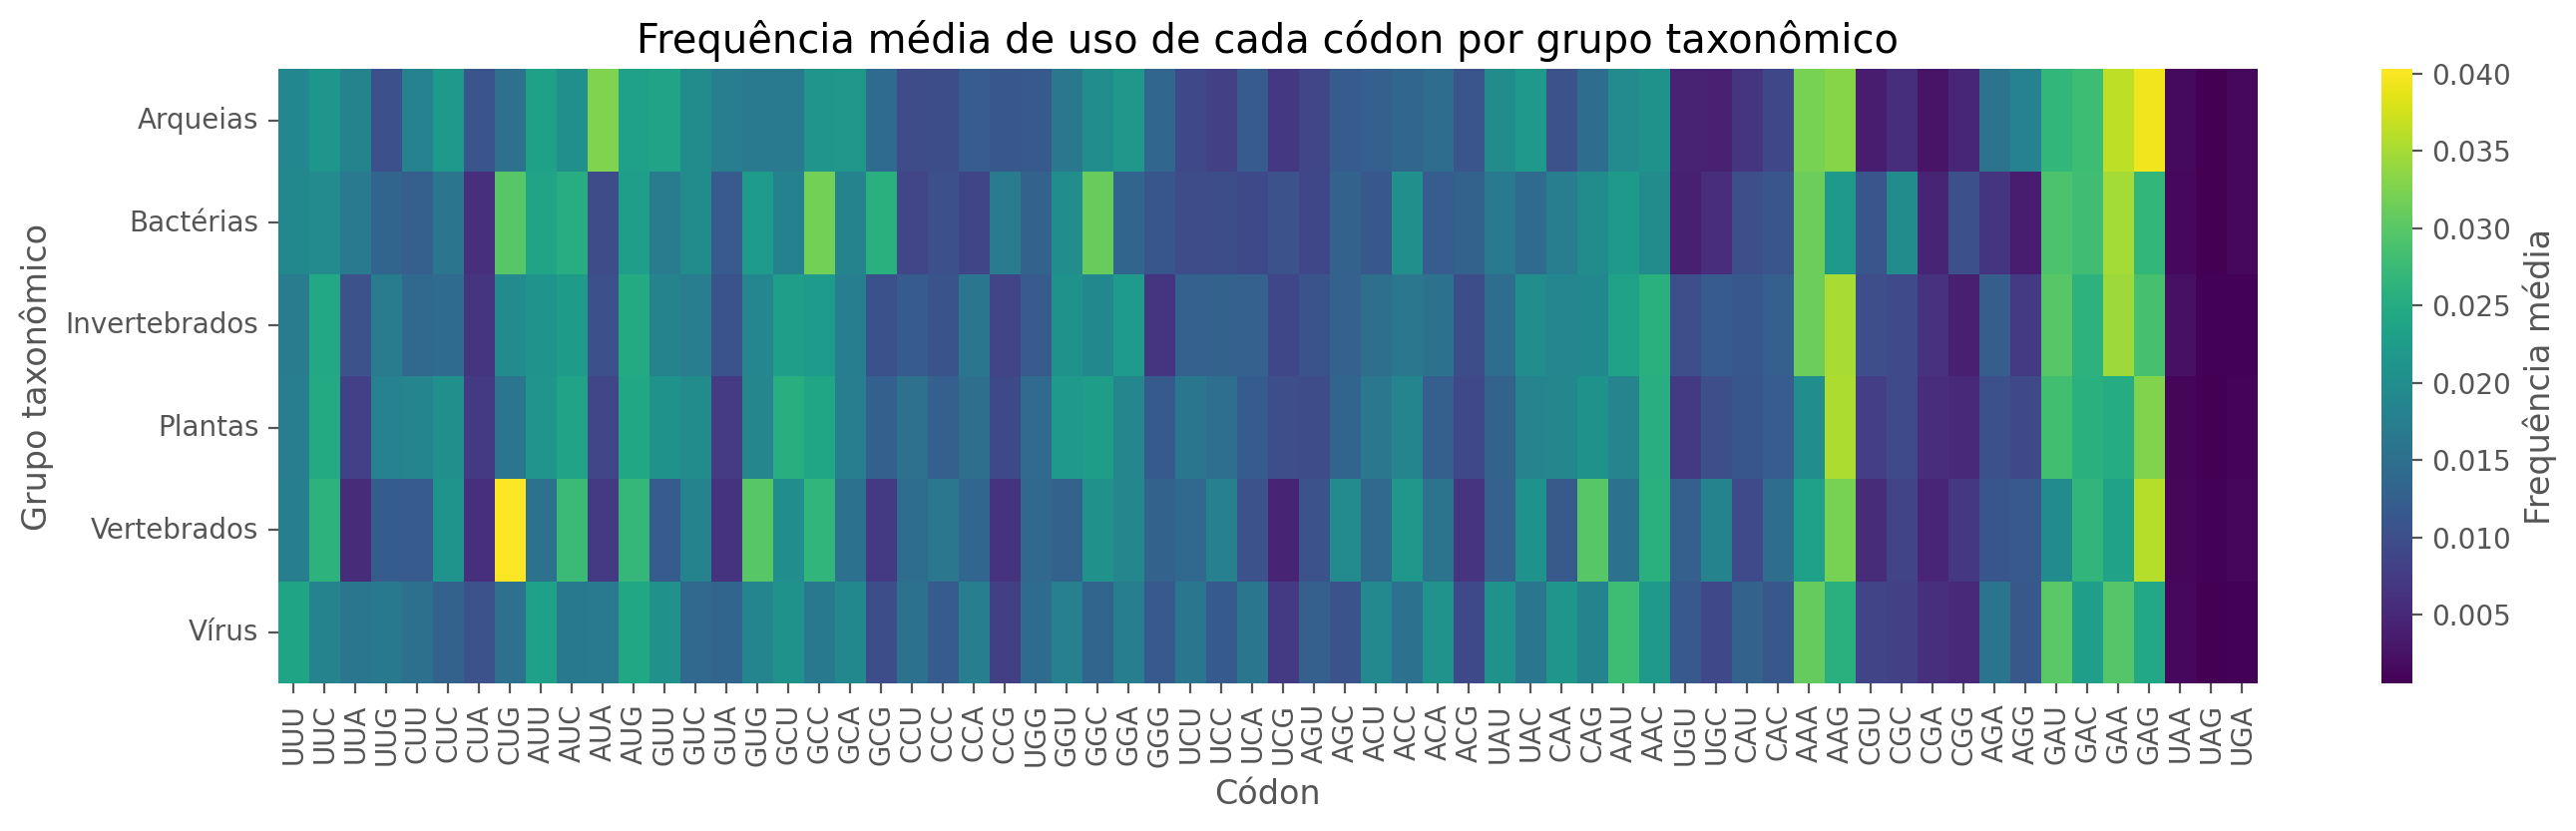

In [244]:
media_por_grupo = df_treino.groupby("Grupo")[colunas_codons].mean()

figura, eixo = plt.subplots(figsize=(16, 4))
sns.heatmap(
    media_por_grupo,
    cmap="viridis",
    ax=eixo,
    cbar_kws={"label": "Frequência média"},
)
eixo.set(
    xlabel="Códon",
    ylabel="Grupo taxonômico",
    title="Frequência média de uso de cada códon por grupo taxonômico",
);

$ \ \ \ \ \ $ Em todos os grupos, os códons de parada (UAA, UAG e UGA) são os menos frequentes. Isso já era esperado, já que cada gene possui apenas um códon de parada. Alguns códons, como AAA e AAG (lisina), GAA e GAG (ácido glutâmico) e GAU (ácido aspártico), são frequentes em quase todos os grupos, refletindo a abundância desses aminoácidos nas proteínas. Assim, o mapa reflete tanto a composição de aminoácidos das proteínas quanto a preferência por determinados códons sinônimos.

$ \ \ \ \ \ $ Apesar dessas semelhanças, cada grupo apresenta um perfil característico. Os vertebrados se destacam pelo uso muito elevado do códon CUG (leucina) e pela baixa frequência de códons que contêm a sequência CG, como UCG, CCG, ACG e CGA, padrão conhecido como depleção de CpG em genomas de vertebrados [[refs]](#refs). As bactérias também utilizam bastante o CUG, além de GCC e GGC, enquanto raramente utilizam AGA e AGG para codificar a arginina. As arqueias apresentam uso elevado do códon AUA (isoleucina), pouco frequente nos demais grupos. Plantas e invertebrados possuem perfis semelhantes entre si, e os vírus apresentam o perfil mais homogêneo, possivelmente porque o grupo reúne vírus de hospedeiros muito diferentes, cujos padrões de uso de códons tendem a se misturar na média. Essas diferenças indicam que as frequências de códons carregam informações capazes de distinguir os grupos taxonômicos, o que motiva o uso desses atributos nos modelos de classificação.

#### 3.4.3 Uso de Códons Sinônimos: o exemplo da leucina

$ \ \ \ \ \ $ Para observar diretamente o viés de uso de códons, analisamos os seis códons sinônimos do aminoácido ramificado leucina (UUA, UUG, CUU, CUC, CUA e CUG). Para cada organismo, a frequência de cada um desses códons foi dividida pela soma das frequências dos seis, obtendo-se a proporção de uso de cada códon entre os códons da leucina. Dessa forma, o gráfico, feito com a biblioteca `Seaborn` mostra apenas a preferência por determinados códons sinônimos, independentemente da quantidade de leucina presente nas proteínas do organismo. Caso não houvesse nenhuma preferência, cada códon seria utilizado em aproximadamente 1/6 dos casos (linha tracejada).

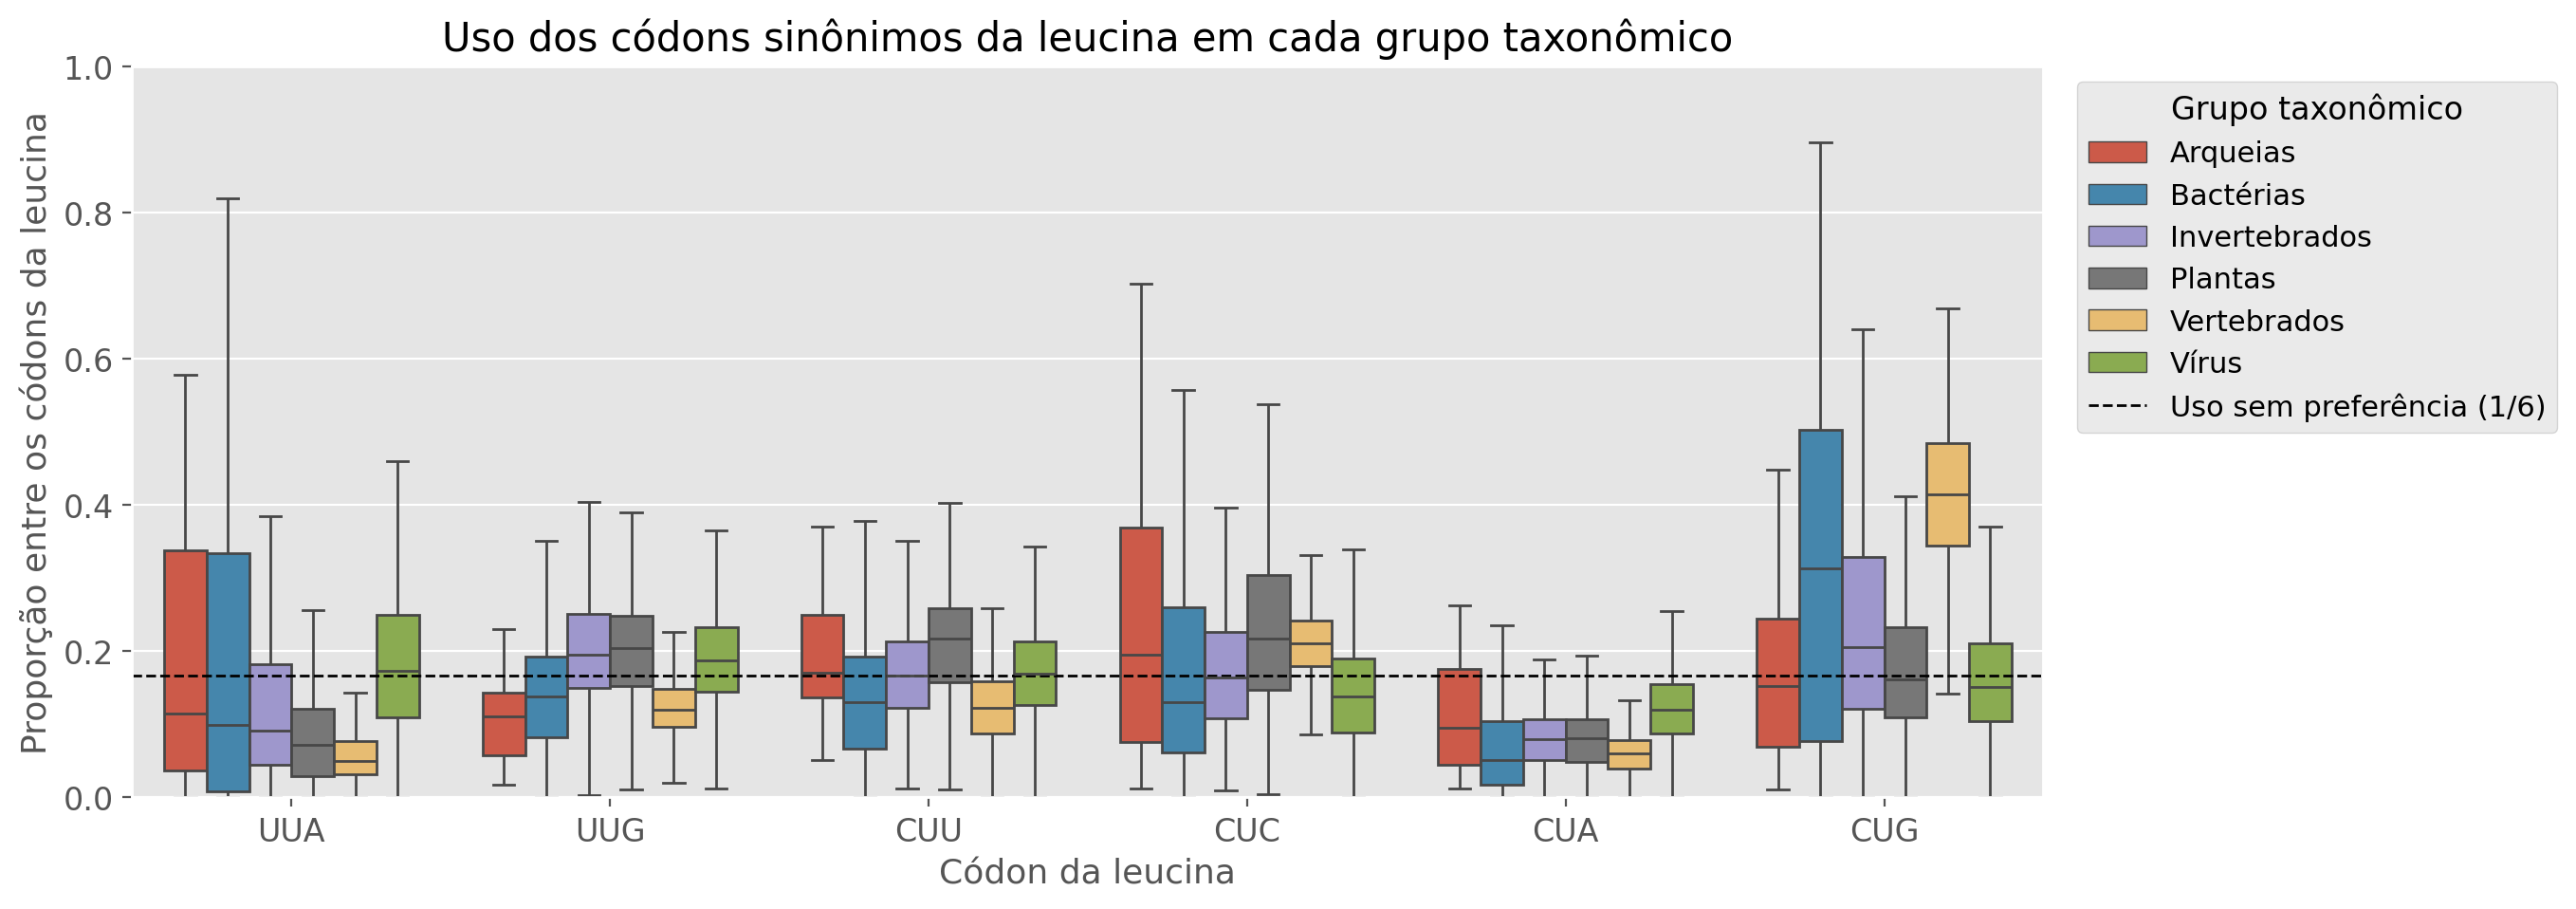

In [245]:
CODONS_LEUCINA = ["UUA", "UUG", "CUU", "CUC", "CUA", "CUG"]

uso_leucina = df_treino[CODONS_LEUCINA].div(df_treino[CODONS_LEUCINA].sum(axis=1), axis=0)
uso_leucina["Grupo"] = df_treino["Grupo"]

dados_longos = uso_leucina.melt(id_vars="Grupo", var_name="Códon", value_name="Proporção")

figura, eixo = plt.subplots(figsize=(13, 5))
sns.boxplot(
    data=dados_longos,
    x="Códon",
    y="Proporção",
    hue="Grupo",
    hue_order=sorted(dados_longos["Grupo"].unique()),
    showfliers=False,
    ax=eixo,
)
eixo.axhline(1 / 6, linestyle="--", color="black", linewidth=1, label="Uso sem preferência (1/6)")

eixo.set_title("Uso dos códons sinônimos da leucina em cada grupo taxonômico", fontsize=15)
eixo.set_xlabel("Códon da leucina", fontsize=13)
eixo.set_ylabel("Proporção entre os códons da leucina", fontsize=13)
eixo.tick_params(labelsize=12)
eixo.set_ylim(0, 1)

eixo.legend(
    title="Grupo taxonômico",
    fontsize=11,
    title_fontsize=12,
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
);

$ \ \ \ \ \ $ Para ter os valores exatos das medianas, podemos utilizar o método `unstack` que transforma o resultado em uma tabela com os grupos nas linhas e os códons nas colunas. 

In [246]:
dados_longos.groupby(["Grupo", "Códon"])["Proporção"].median().unstack().round(2)

Códon,CUA,CUC,CUG,CUU,UUA,UUG
Grupo,,,,,,
Arqueias,0.10,0.20,0.15,0.17,0.12,0.11
Bactérias,0.05,0.13,0.31,0.13,0.10,0.14
Invertebrados,0.08,0.16,0.21,0.17,0.09,0.20
Plantas,0.08,0.22,0.16,0.22,0.07,0.20
Vertebrados,0.06,0.21,0.42,0.12,0.05,0.12
Vírus,0.12,0.14,0.15,0.17,0.17,0.19


$ \ \ \ \ \ $ Analisando tanto o gráfico quanto a tabela, é perceptível como os vertebrados apresentam o viés mais forte e mais consistente entre os organismos. O códon CUG corresponde a cerca de 40% dos códons de leucina, mais que o dobro do esperado sem preferência, enquanto UUA e CUA são raramente utilizados. Bactérias e arqueias apresentam grande variação dentro do próprio grupo, com organismos que preferem o códon UUA e outros que preferem o CUG, o que é coerente com a influência do conteúdo de GC do genoma observada na análise de correlação acima. Os vírus apresentam proporções mais próximas do uso uniforme, possivelmente por reunirem vírus de hospedeiros muito diferentes, de modo que as preferências se misturam entre os grupos. Já as plantas e os invertebrados apresentam perfis intermediários e semelhantes entre si. Em todos os grupos, o códon CUA é pouco utilizado. Ambos usam mais UUG, CUU e CUC e pouco UUA e CUA. Os invertebrados também usam bastante o CUG.

$ \ \ \ \ \ $ Esses resultados mostram que o viés de uso de códons varia entre os grupos taxonômicos, o que, mais uma vez, justifica o uso desses atributos para a classificação. Por outro lado, a grande variação dentro de alguns grupos, especialmente bactérias e arqueias, sugere que esses grupos podem ser mais difíceis de distinguir, o que verificaremos na avaliação dos modelos.

#### 3.4.4 Correlação entre os Códons 

$ \ \ \ \ \ $ Para verificar se os atributos carregam informações independentes ou redundantes, calculamos o coeficiente de correlação de Pearson entre as frequências de cada par de códons, utilizando apenas o conjunto de treino. O coeficiente de Pearson varia de -1 a 1. Valores próximos de 1 (em vermelho) indicam que dois códons tendem a ser mais frequentes nos mesmos organismos, valores próximos de -1 (em azul) indicam que, quando um códon é mais frequente, o outro tende a ser menos (correlação negativa), e valores próximos de 0 indicam ausência de relação linear.

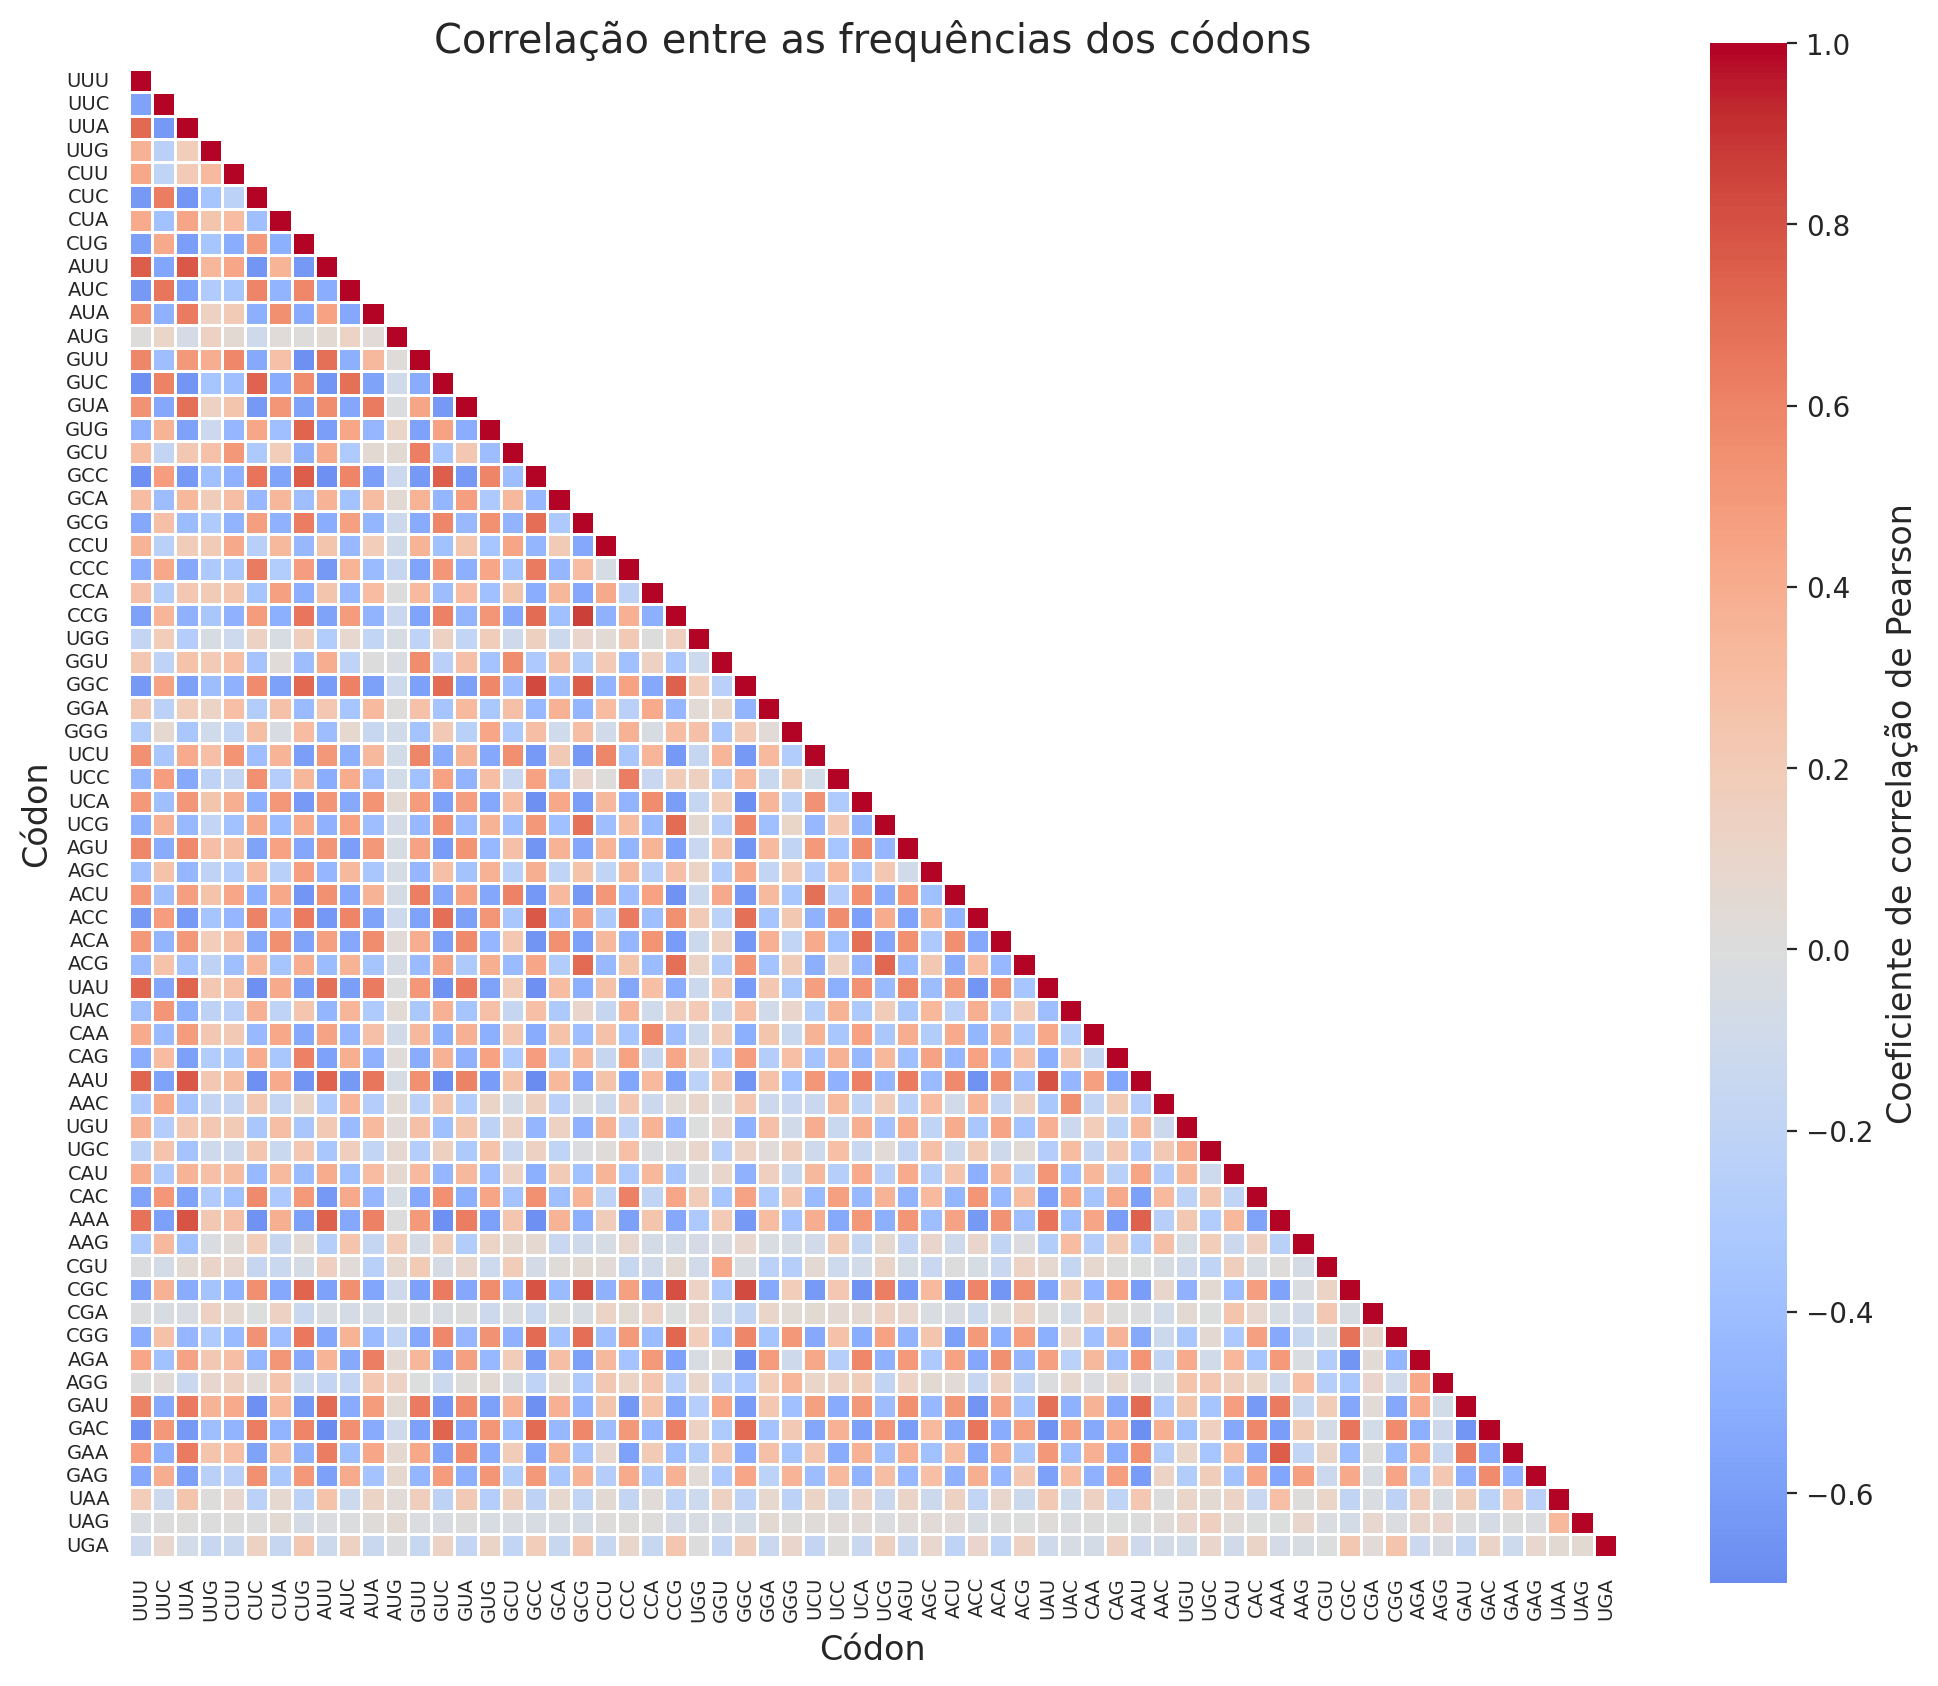

In [247]:
m_corr = X_treino[colunas_codons].corr()
mascara = np.triu(np.ones_like(m_corr, dtype=bool), k=1)
mapa_de_cor = "coolwarm"

with sns.axes_style("white"):
    figura, eixo = plt.subplots(figsize=(12, 10))
    sns.heatmap(
        m_corr,
        mask=mascara,
        cmap=mapa_de_cor,
        center=0,
        square=True,
        linewidths=0.5,
        ax=eixo,
        xticklabels=True,
        yticklabels=True,
        cbar_kws={"label": "Coeficiente de correlação de Pearson"},
    )
    eixo.tick_params(labelsize=7)
    eixo.set(
        xlabel="Códon",
        ylabel="Códon",
        title="Correlação entre as frequências dos códons",
    );

$ \ \ \ \ \ $ O gráfico mostra que muitos pares de códons apresentam correlações fortes, positivas ou negativas, o que indica que os atributos são redundantes entre si. Além disso, observa-se um padrão regular, semelhante a um tabuleiro de xadrez. Como os códons estão ordenados de modo que a terceira base alterna entre U, C, A e G, esse padrão indica que códons terminados em A ou U tendem a ser frequentes nos mesmos organismos, assim como os terminados em G ou C, enquanto os dois tipos apresentam correlação negativa entre si. Esse comportamento é coerente com a influência do conteúdo de GC do genoma sobre o uso de códons: organismos com genomas ricos em G e C tendem a preferir códons terminados nessas bases [[refs]](#refs). Já os códons de parada apresentam correlações próximas de zero com os demais, pois aparecem apenas uma vez em cada gene.

$ \ \ \ \ \ $ A forte correlação entre os atributos, somada ao fato de que as frequências sempre somam 1, reforça que a informação contida nos 64 códons pode ser representada por um número menor de variáveis, o que motiva o uso da análise de componentes principais (PCA), que iremos introduzir. 

#### 3.4.5 Análise de Componentes Principais (PCA)

$ \ \ \ \ \ $ A análise de componentes principais (PCA) é uma técnica de redução de dimensionalidade que cria novas variáveis, chamadas componentes principais, a partir de combinações lineares dos atributos originais [[refs]](#refs). Essas componentes são obtidas a partir dos autovetores da matriz de covariância dos dados e são ordenadas de acordo com a variância que explicam: a primeira componente corresponde à direção em que os organismos mais diferem entre si, a segunda captura a maior parte da variância restante, e assim por diante. Além disso, as componentes não são correlacionadas entre si. Quando todas as componentes são mantidas, nenhuma informação é perdida. A redução de dimensionalidade ocorre quando apenas as primeiras componentes são utilizadas.

$ \ \ \ \ \ $ Neste trabalho, o PCA é utilizado em dois momentos. Nesta seção, ele é aplicado de forma exploratória, para avaliar o quanto os atributos são redundantes e como os grupos taxonômicos se distribuem no espaço das componentes principais. Na etapa de modelagem, o PCA é incluído no pipeline de cada modelo, com o número de componentes tratado como um hiperparâmetro otimizado pelo `Optuna`. Como o PCA busca as direções de maior variância, ele é sensível à escala dos atributos, por isso, os dados de treino foram normalizados - com o Normalizador Padrão que faz com que a média dos valores seja nula e o desvio padrão igual a 1 - antes da análise.

Componentes necessárias para explicar 90% da variância: 33


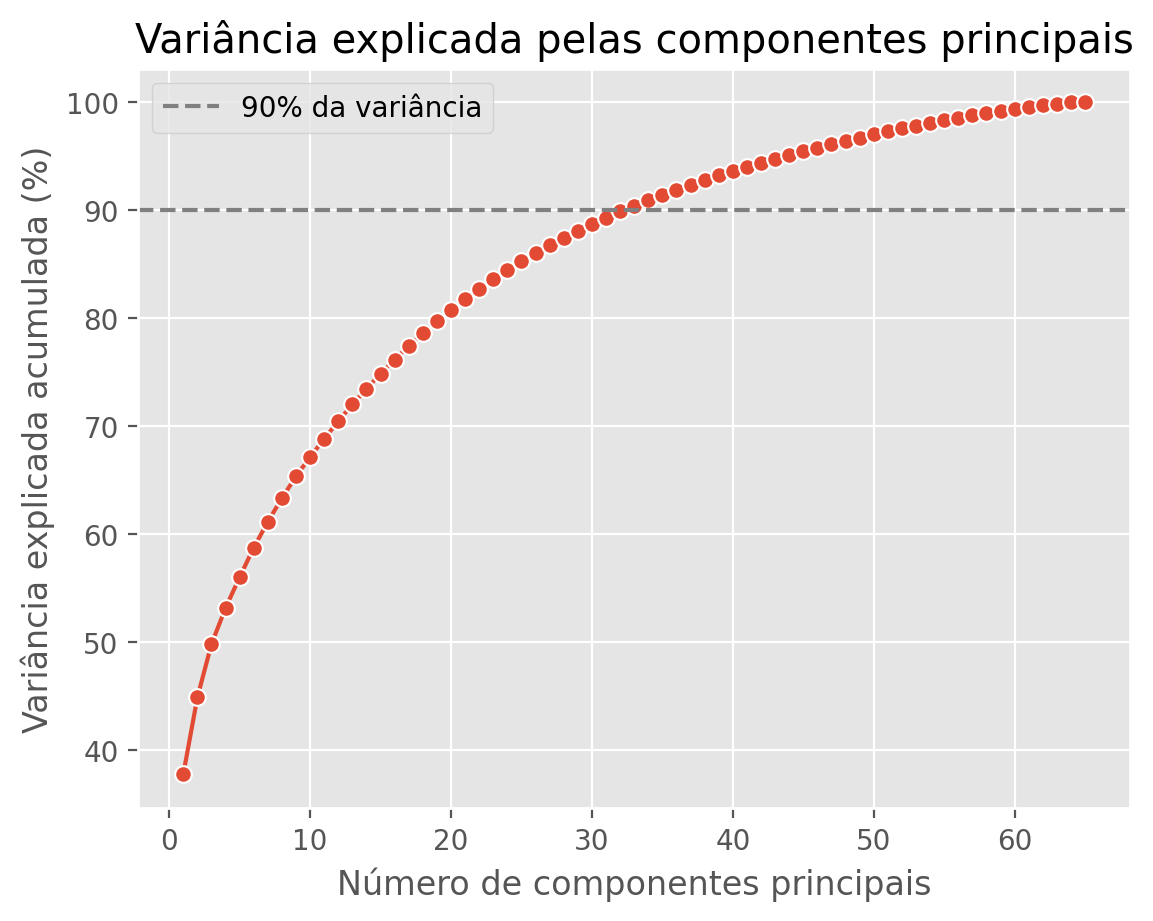

In [248]:
normalizador = StandardScaler()
normalizador.fit(X_treino)
X_treino_normalizado = normalizador.transform(X_treino)

pca = PCA()
pca.fit(X_treino_normalizado)

variancia_acumulada = np.cumsum(pca.explained_variance_ratio_) * 100
num_componentes_90 = np.argmax(variancia_acumulada >= 90) + 1
print(f"Componentes necessárias para explicar 90% da variância: {num_componentes_90}")

eixo = sns.lineplot(x=range(1, len(variancia_acumulada) + 1), y=variancia_acumulada, marker="o")
eixo.axhline(90, linestyle="--", color="gray", label="90% da variância")
eixo.set(
    xlabel="Número de componentes principais",
    ylabel="Variância explicada acumulada (%)",
    title="Variância explicada pelas componentes principais"
)
eixo.legend();

$ \ \ \ \ \ $ O gráfico mostra a variância explicada acumulada em função do número de componentes principais. A primeira componente explica sozinha um pouco menos de 40% da variância dos dados, e as duas primeiras juntas, cerca de 45%. A partir daí, cada nova componente acrescenta cada vez menos informação, e são necessárias 33 componentes para explicar 90% da variância, o que é aproximadamente metade dos 65 atributos originais. Isso confirma a redundância entre os atributos observada na análise de correlação, mas também indica que a informação não está concentrada em poucas componentes. Por esse motivo, em vez de fixar o número de componentes, essa escolha será deixada para o Optuna, no intervalo de 2 a 65 componentes.

$ \ \ \ \ \ $ Para facilitar a visualização e o entendimento do PCA, vamos projetar os organismos contemplados nas duas primeiras componentes principais:

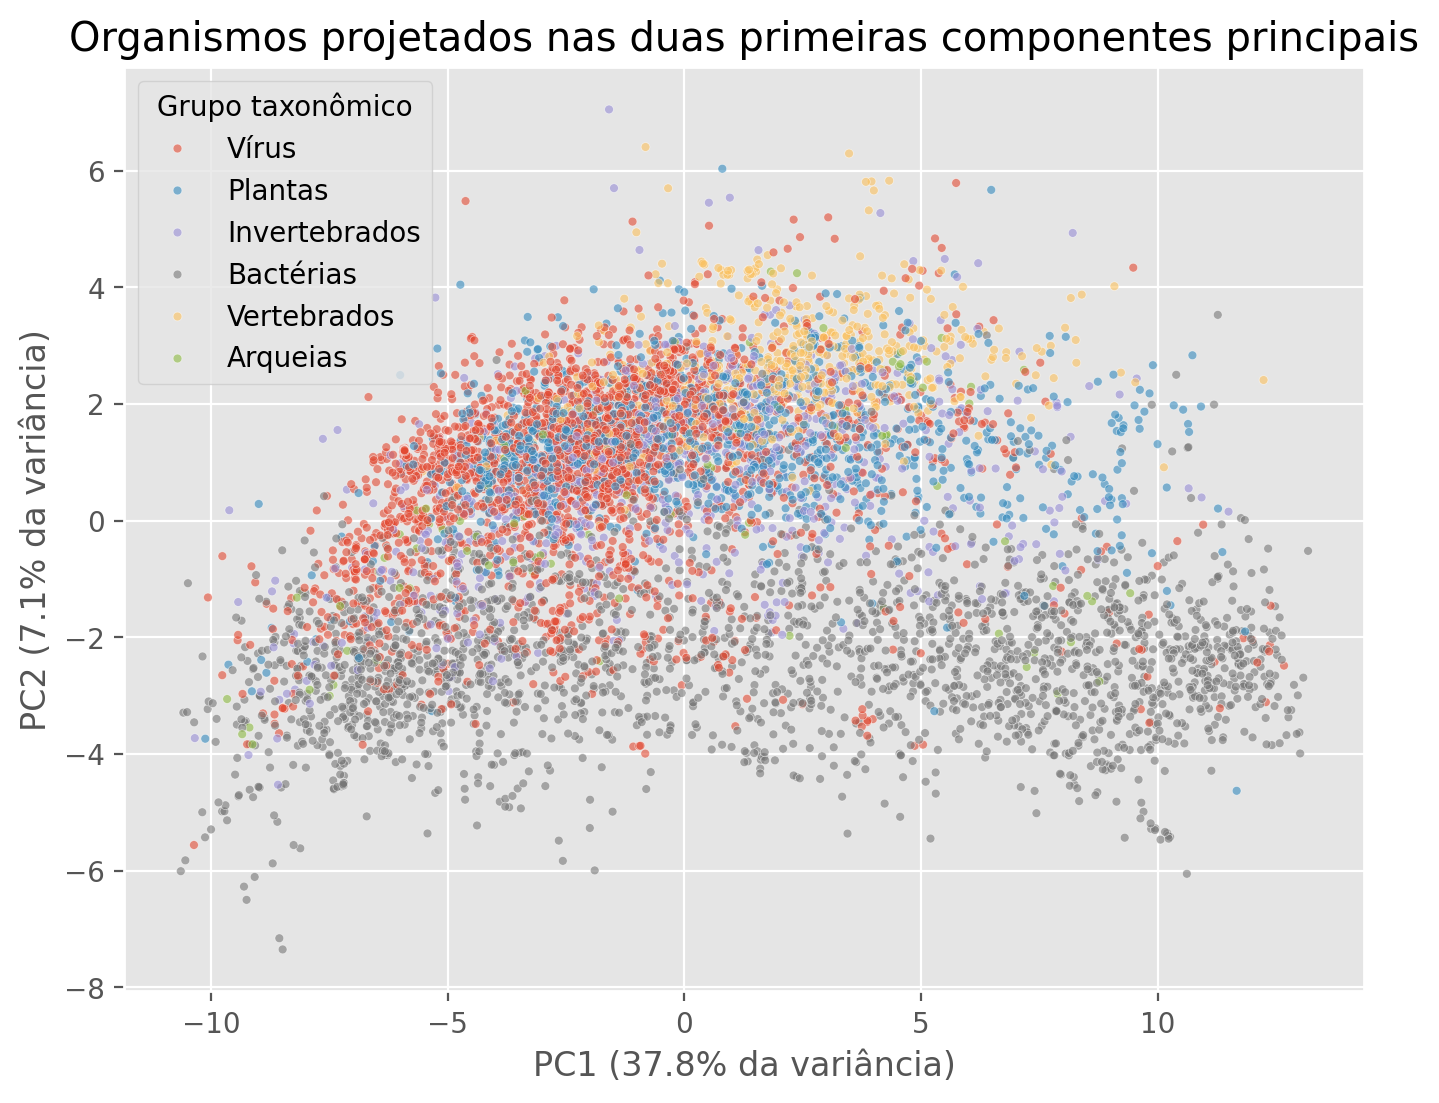

In [249]:
componentes = pca.transform(X_treino_normalizado)
variancia = pca.explained_variance_ratio_ * 100

figura, eixo = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=y_treino, s=10, alpha=0.6, ax=eixo)
eixo.set(
    xlabel=f"PC1 ({variancia[0]:.1f}% da variância)",
    ylabel=f"PC2 ({variancia[1]:.1f}% da variância)",
    title="Organismos projetados nas duas primeiras componentes principais",
)
eixo.legend(title="Grupo taxonômico");

$ \ \ \ \ \ $ Observa-se que as bactérias se concentram principalmente na região de valores negativos da segunda componente, separando-se parcialmente dos demais grupos. Ao mesmo tempo, as bactérias se distribuem ao longo de toda a primeira componente, o que é coerente com a grande variação no uso de códons observada dentro desse grupo e sugere que a primeira componente esteja relacionada ao conteúdo de GC do genoma. Os vertebrados ocupam uma região própria, na parte superior do gráfico, enquanto vírus, plantas e invertebrados se sobrepõem bastante. As arqueias, por serem pouco numerosas, ficam praticamente encobertas pelos demais grupos e dispersas pelo gráfico.

$ \ \ \ \ \ $ Como as duas primeiras componentes explicam apenas cerca de 45% da variância, é esperado que vários grupos se sobreponham nessa projeção. Os modelos de classificação, por sua vez, utilizam um número maior de componentes e podem identificar fronteiras de decisão mais complexas. Ainda assim, o gráfico sugere que a distinção entre vírus, plantas e invertebrados pode ser mais difícil, o que será verificado na avaliação dos modelos.

<a id="base"></a>
### 3.5 Modelo Baseline

$ \ \ \ \ \ $ Com toda a parte preparatória tendo sido feita, os dados terem sido separados em treino e teste corretamente evidando vazamento de dados, e a análise exploratória concluída, permitindo um conhecimento mais aprofundado sobre o DataSet, podemos começar a induzir os modelos através de algoritmos conhecidos de Aprendizado de Máquina

$ \ \ \ \ \ $ Antes de induzir qualquer modelo mais complexo, podemos induzir o Modelo Baseline, também chamado de dummy, linha de base ou modelo fictício, é um modelo mais simples que é utilizado para comparar o desempenho desses modelos mais complexos. Empregando a estratégia da classe majoritária, o classificador realiza suas previsões atribuindo sempre a categoria mais frequente observada no conjunto de treinamento, ou seja, a moda do target, que nesse caso é o grupo dos vírus.  Seguindo a mesma estratégia que será utilizada para os demais modelos, seu desempenho foi estimado por validação cruzada estratificada com 5 folds no conjunto de treino.

In [252]:
modelo_baseline = DummyClassifier(strategy="most_frequent")

f1_baseline = cross_val_score(
    modelo_baseline, X_treino, y_treino, scoring="f1_macro", cv=NUM_FOLDS
)
acuracia_baseline = cross_val_score(
    modelo_baseline, X_treino, y_treino, scoring="accuracy", cv=NUM_FOLDS
)

print(f"F1 macro do baseline: {f1_baseline.mean() * 100:.1f}% ± {f1_baseline.std() * 100:.1f}%")
print(f"Acurácia do baseline: {acuracia_baseline.mean() * 100:.1f}% ± {acuracia_baseline.std() * 100:.1f}%")

F1 macro do baseline: 8.3% ± 0.0%
Acurácia do baseline: 32.9% ± 0.0%


$ \ \ \ \ \ $ Para avaliar todos os modelos a seguir e inclusive o baseline foram utilizadas duas métricas. A **acurácia** é a proporção de organismos classificados corretamente [[refs]](#refs):

$$
\text{Acurácia} = \frac{\text{número de previsões corretas}}{\text{número total de previsões}}
$$

$ \ \ \ \ \ $ Apesar de ser simples e intuitiva, a acurácia pode ser enganosa quando as classes são desbalanceadas, pois um modelo que acerte apenas as classes mais frequentes pode obter um valor alto mesmo sem identificar as classes menos numerosas.

$ \ \ \ \ \ $ O **F1 macro** contorna esse problema. Para cada classe, calculam-se duas medidas: a **precisão**, que indica, entre os organismos que o modelo atribuiu a determinado grupo, a proporção que realmente pertence a ele; e a **sensibilidade** (*recall*), que indica, entre os organismos que pertencem a determinado grupo, a proporção que o modelo identificou corretamente. O **F1** de cada classe combina essas duas medidas por meio de sua média harmônica:

$$
F_1 = 2 \cdot \frac{\text{precisão} \cdot \text{sensibilidade}}{\text{precisão} + \text{sensibilidade}}
$$

$ \ \ \ \ \ $ A média harmônica só é alta quando a precisão e a sensibilidade são altas ao mesmo tempo: um modelo que atribui muitos organismos a um grupo pode encontrar todos os seus membros (sensibilidade alta), mas errará muito ao fazê-lo (precisão baixa), o que reduz o F1. Por fim, o **F1 macro** é a média simples do F1 das seis classes [[refs]](#refs), de modo que todos os grupos taxonômicos têm o mesmo peso no resultado, independentemente do número de organismos. Assim, um modelo só obtém um F1 macro alto se classificar bem todos os grupos, inclusive os menos numerosos, como as arqueias. Ambas as métricas variam de 0 a 1 (ou de 0% a 100%), e valores maiores indicam melhor desempenho.

$ \ \ \ \ \ $ Com a explicação das métricas de desempenho, podemos interpretar os resultados obtidos. O baseline obteve acurácia de 32,9% e F1 macro de 8,3%. A acurácia corresponde exatamente à proporção de vírus no conjunto de treino. Como o modelo prevê sempre essa classe, ele acerta todos os vírus e erra todos os demais organismos. Já o F1 macro, que dá o mesmo peso a todas as classes, revela que o modelo não é capaz de identificar nenhum dos outros cinco grupos taxonômicos, já que o F1 dessas classes é zero. Essa diferença entre as duas métricas ilustra por que a acurácia não é adequada para dados desbalanceados e justifica a escolha do F1 macro como métrica principal.

$ \ \ \ \ \ $ O desvio padrão nulo entre os folds também é esperado: como a validação cruzada é estratificada, cada *fold* possui a mesma proporção de vírus, e o baseline obtém exatamente o mesmo resultado em todos eles. Esses valores servem como referência mínima para os modelos induzidos a seguir.

<a id="opt"></a>
### 3.6 Otimização de hiperparâmetros com optuna

$ \ \ \ \ \ $ Para otimizar os hiperparâmetros utilizando `optuna`, utilizaremos como base o Material Didático não publicado do Prof. Dr. Daniel Roberto Cassar "Otimização de hiperparâmetros com optuna" [[refs]](#refs). O optuna é uma biblioteca de otimização de hiperparâmetros que aceita tanto parâmetros numéricos (como o número de vizinhos do k-NN) quanto categóricos (tipo de normalizador, por exemplo). Diferentemente da busca em grade, que testa todas as combinações possíveis através de um produto cartesiano dos hiperparâmetros, e da busca aleatória, que sorteia combinações sem critério, o optuna usa os resultados das tentativas anteriores para escolher as próximas, concentrando a busca nas regiões mais promissoras, o que consiste no amostrador TPE (Tree-structured Parzen Estimator).

#### 3.6.0 Pré-Processamento no Pipeline

$ \ \ \ \ \ $ Antes de otimizar os hiperparâmetros, definimos as etapas de pré-processamento que farão parte do *pipeline* de cada modelo: a normalização dos dados e a redução de dimensionalidade com PCA. Essas etapas aprendem parâmetros a partir dos dados (como a média e o desvio padrão de cada atributo, no caso da normalização padrão, e as direções das componentes, no caso do PCA) e, por isso, foram incluídas no pipeline, que garante que sejam ajustadas apenas com os dados de treino de cada etapa da validação cruzada, evitando o vazamento de dados.

$ \ \ \ \ \ $ A função `cria_etapas_preprocessamento` deixa o optuna escolher o tipo de normalizador (padrão, mínimo e máximo ou máximo absoluto) e o número de componentes principais mantidas, de 2 a 65. Com 65 componentes, o PCA não reduz a dimensionalidade, apenas rotaciona os eixos; assim, o `optuna` também pode concluir que a redução não é vantajosa para determinado modelo. Essa função está sendo definida aqui, pois é utilizada por todos os cinco algoritmos, evitando a repetição do código.

In [253]:
NORMALIZADORES = {
    "padrao": StandardScaler,
    "min_max": MinMaxScaler,
    "max_abs": MaxAbsScaler,
}

def cria_etapas_preprocessamento(trial):
    """Cria as etapas de pré-processamento escolhidas pelo Optuna."""

    nome_normalizador = trial.suggest_categorical("normalizador", list(NORMALIZADORES))
    normalizador = NORMALIZADORES[nome_normalizador]()

    num_componentes = trial.suggest_int("num_componentes_pca", 2, len(ATRIBUTOS))
    pca = PCA(n_components=num_componentes)

    return [normalizador, pca]

#### 3.6.1 Função objetivo

$ \ \ \ \ \ $ A função objetivo é a função que o optuna busca otimizar. A cada tentativa, ela cria um modelo com os hiperparâmetros sugeridos, avalia seu desempenho por validação cruzada no conjunto de treino e retorna a média do F1 macro entre os folds. A função foi adaptada do material disponibilizado em aula sobre o `optuna` [[X]](#refs) em dois pontos: como otimizaremos cinco algoritmos, ela recebe como argumento a função que cria cada modelo (`cria_instancia_modelo`); e, como o objetivo é maximizar o F1 macro, os estudos foram criados com `direction="maximize"`.

In [144]:
def funcao_objetivo(trial, X, y, num_folds, cria_instancia_modelo):
    """Função objetivo do optuna.

    Args:
      trial: objeto tipo Trial do optuna.
      X: atributos do conjunto de treino.
      y: target do conjunto de treino.
      num_folds: número de folds da validação cruzada.
      cria_instancia_modelo: função que cria o modelo a partir do trial.

    Returns:
      Média do F1 macro na validação cruzada.
    """

    modelo = cria_instancia_modelo(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring=METRICA,
        cv=num_folds,
    )

    return metricas.mean()

#### 3.6.2 Regressão Logística

$ \ \ \ \ \ $ Apesar do nome, a regressão logística é um algoritmo de classificação, que calcula uma combinação linear dos atributos para cada classe e transforma esses valores em probabilidades, atribuindo cada organismo à classe de maior probabilidade. Por ser um modelo linear, ela só consegue separar as classes por meio de fronteiras de decisão lineares (planos, no espaço dos atributos).

In [145]:
def cria_instancia_reglog(trial):
    """Cria uma instância do modelo de regressão logística.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "C": trial.suggest_float("C", 1e-3, 1e3, log=True),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        # argumentos fixos
        "max_iter": 2000,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        LogisticRegression(**parametros),
    )

    return modelo

$ \ \ \ \ \ $ Foram otimizados dois hiperparâmetros, além do normalizador e do número de componentes do PCA. O `C` controla a regularização, isto é, a penalização de coeficientes muito grandes: valores pequenos de `C` impõem uma regularização forte, que simplifica o modelo e reduz o risco de sobreajuste, enquanto valores grandes permitem que o modelo se ajuste mais aos dados. Como esse hiperparâmetro varia em várias ordens de grandeza, ele foi amostrado em escala logarítmica, entre 0,001 e 1000. O peso das classes (`class_weight`) pode ser nenhum ou balanceado. Nesse último caso, os erros nas classes menos numerosas, como as arqueias, recebem um peso maior durante o treino, o que pode ajudar a lidar com o desbalanceamento. O número máximo de iterações foi fixado em 2000 para garantir a convergência do algoritmo.

In [262]:
NOME_DO_ESTUDO = "reglog_codon_usage"

objeto_de_estudo_reglog = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
)

In [266]:
if len(objeto_de_estudo_reglog.trials) == 0:
    objeto_de_estudo_reglog.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "C": 1.0,
            "peso_classes": None,
        }
    )

In [267]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_reglog,
)

if len(objeto_de_estudo_reglog.trials) < NUM_TENTATIVAS:
    objeto_de_estudo_reglog.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [265]:
melhor_trial_reglog = objeto_de_estudo_reglog.best_trial

print(f"Número do melhor trial: {melhor_trial_reglog.number}")
print(f"F1 macro do melhor trial: {melhor_trial_reglog.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_reglog.params}")

Número do melhor trial: 246
F1 macro do melhor trial: 85.7%
Parâmetros do melhor trial: {'C': 61.73810893956523, 'peso_classes': None, 'normalizador': 'min_max', 'num_componentes_pca': 65}


In [152]:
print("Total de tentativas:", len(objeto_de_estudo_reglog.trials))

df_tentativas = objeto_de_estudo_reglog.trials_dataframe()
df_tentativas["state"].value_counts()

Total de tentativas: 200


state
COMPLETE    200
Name: count, dtype: int64

<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

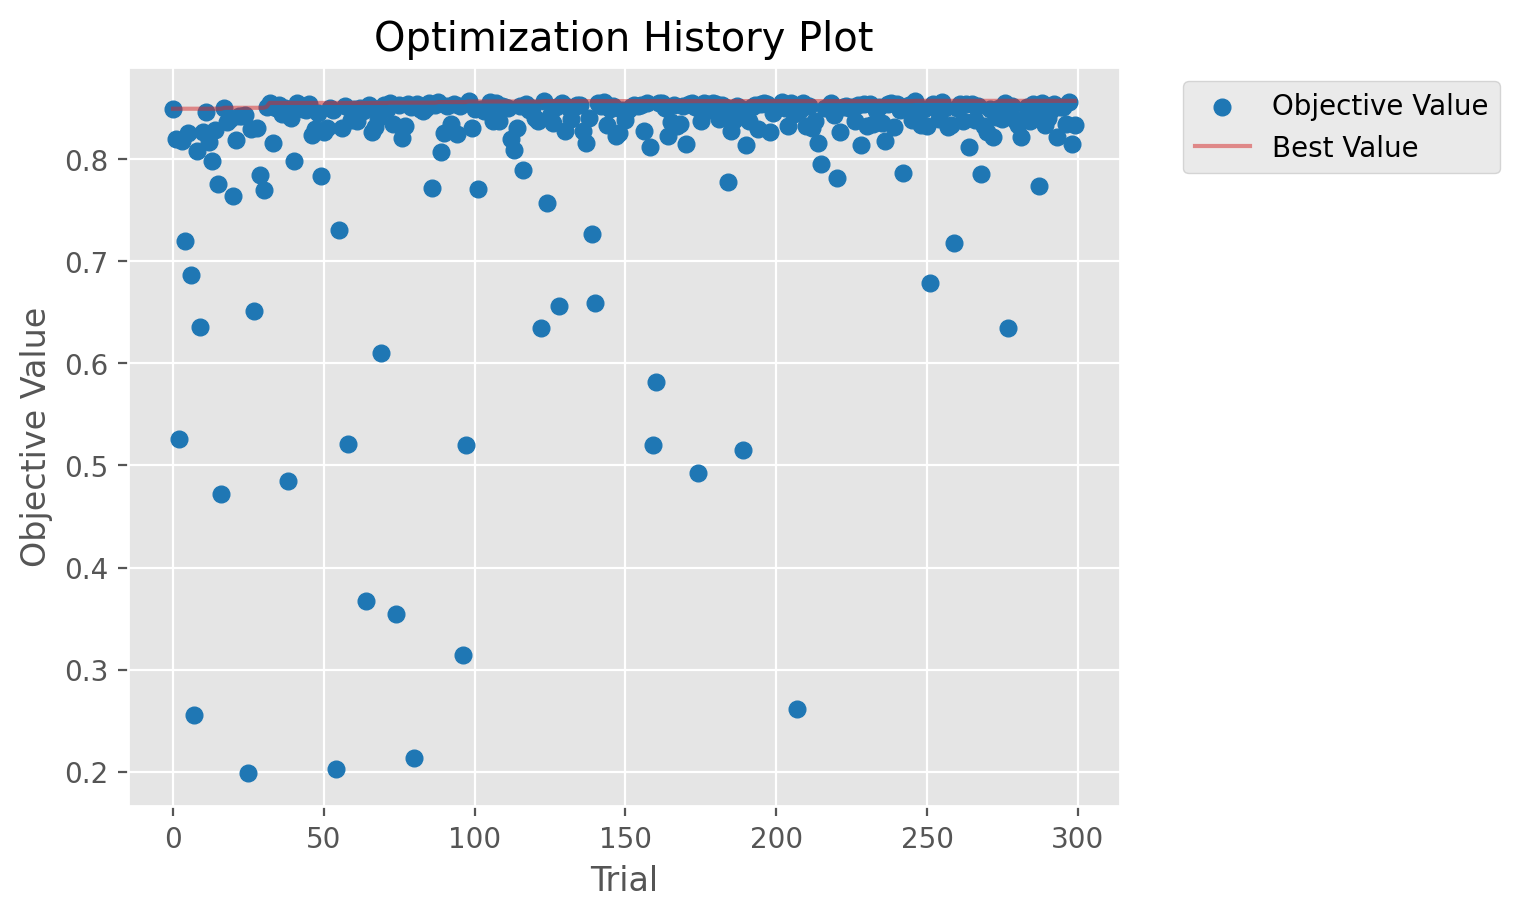

In [289]:
vis.plot_optimization_history(objeto_de_estudo_reglog)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

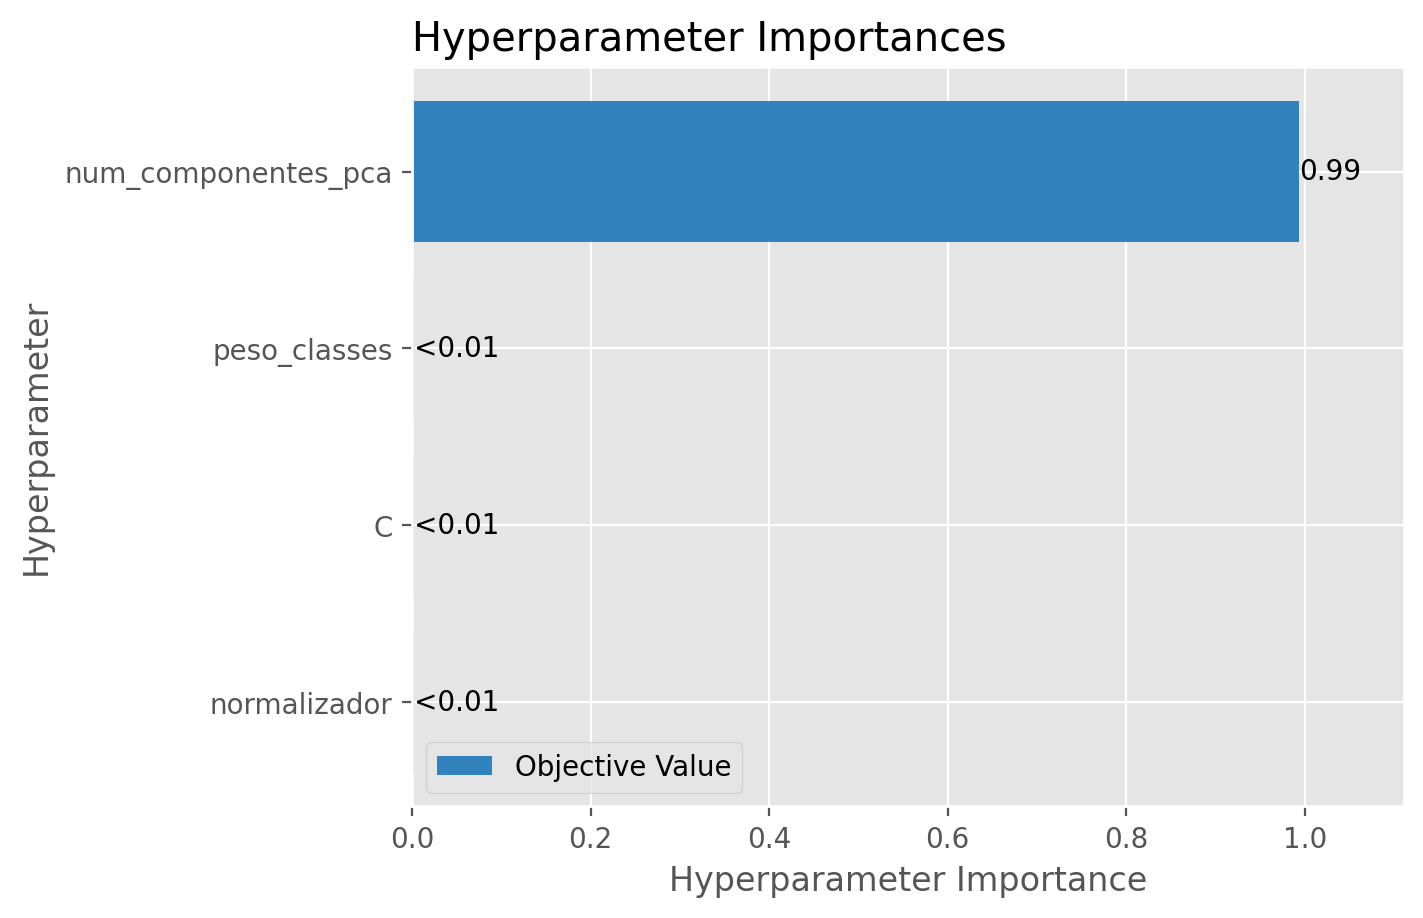

In [288]:
vis.plot_param_importances(objeto_de_estudo_reglog)

#### 3.6.3 k-vizinhos mais próximos (k-NN)

In [160]:
def cria_instancia_knn(trial):
    """Cria uma instância do modelo k-NN.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "n_neighbors": trial.suggest_int("num_vizinhos", 1, 50),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "p": trial.suggest_float("potencia_minkowski", 1, 2),
        # argumentos fixos
        "algorithm": "ball_tree",
        "n_jobs": -1,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        KNeighborsClassifier(**parametros),
    )

    return modelo

In [287]:
NOME_DO_ESTUDO = "knn_codon_usage"

objeto_de_estudo_knn = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
)

In [268]:
if len(objeto_de_estudo_knn.trials) == 0:
    objeto_de_estudo_knn.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "num_vizinhos": 5,
            "pesos": "uniform",
            "potencia_minkowski": 2,
        }
    )

In [269]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_knn,
)

if len(objeto_de_estudo_knn.trials) < NUM_TENTATIVAS:
    objeto_de_estudo_knn.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [164]:
melhor_trial_knn = objeto_de_estudo_knn.best_trial

print(f"Número do melhor trial: {melhor_trial_knn.number}")
print(f"F1 macro do melhor trial: {melhor_trial_knn.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_knn.params}")

Número do melhor trial: 178
F1 macro do melhor trial: 90.8%
Parâmetros do melhor trial: {'num_vizinhos': 1, 'pesos': 'distance', 'potencia_minkowski': 1.8429051527148712, 'normalizador': 'padrao', 'num_componentes_pca': 65}


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

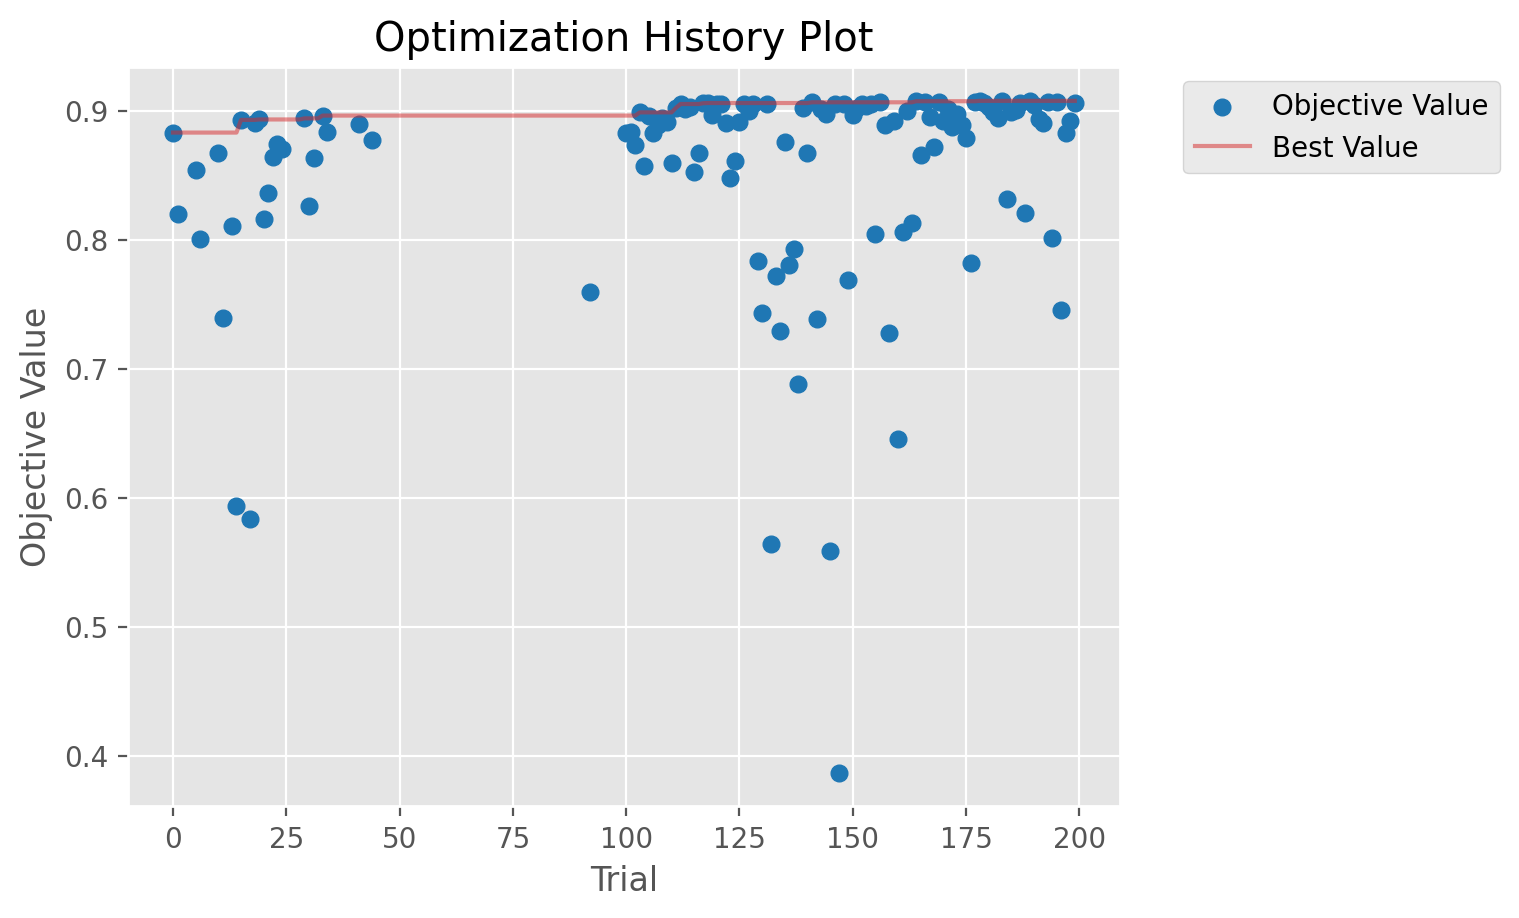

In [285]:
vis.plot_optimization_history(objeto_de_estudo_knn)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

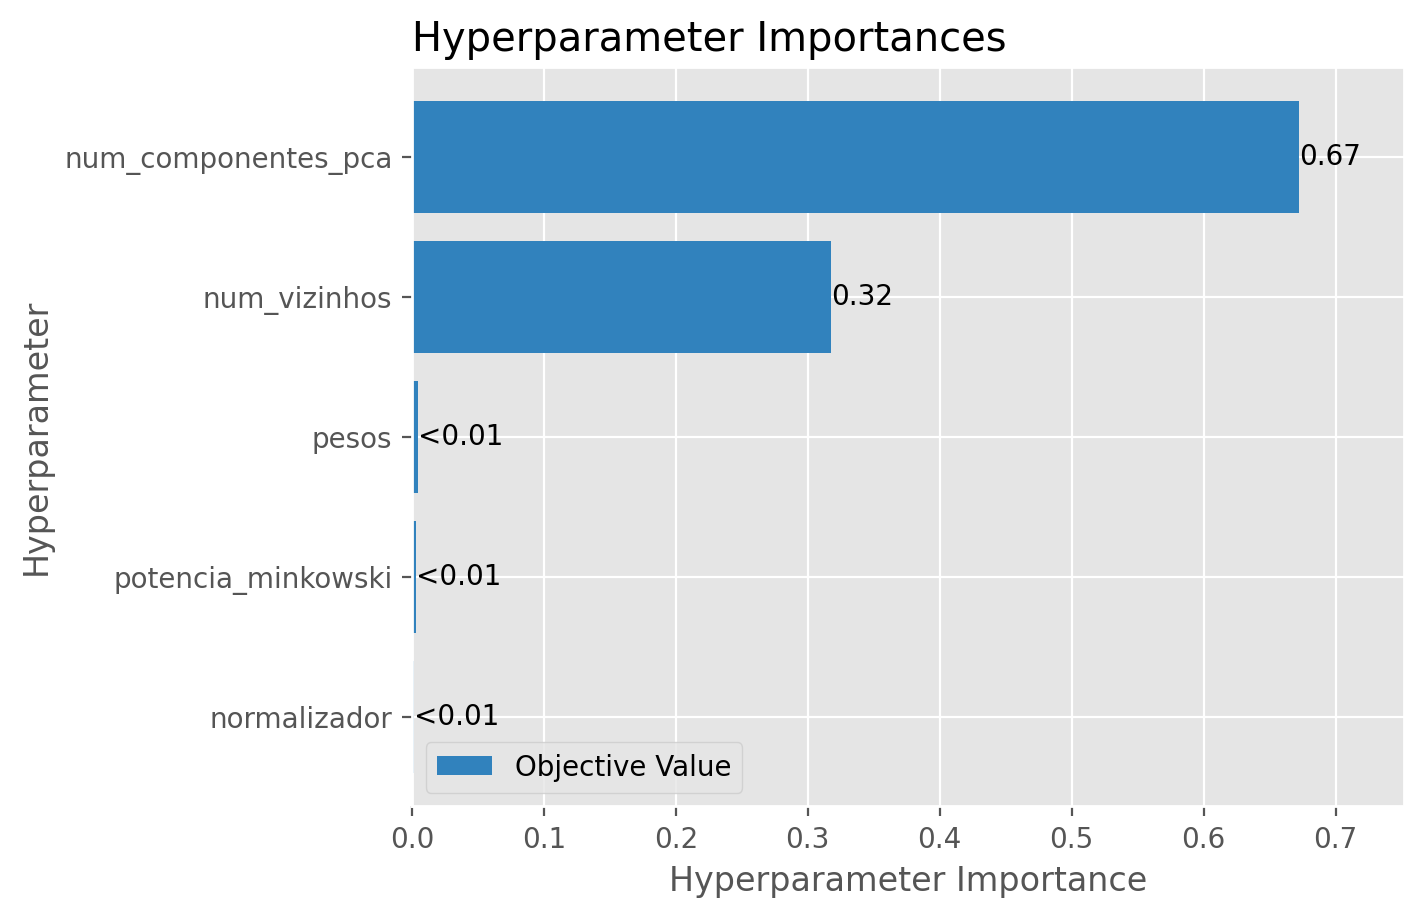

In [286]:
vis.plot_param_importances(objeto_de_estudo_knn)

#### 3.6.4 Árvore de Decisão

In [167]:
def cria_instancia_arvore(trial):
    """Cria uma instância do modelo de árvore de decisão.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "criterion": trial.suggest_categorical("criterio", ["gini", "entropy"]),
        "max_depth": trial.suggest_int("profundidade_maxima", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 50, log=True),
        "max_features": trial.suggest_float("fracao_atributos", 0.1, 1),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        # argumentos fixos
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        DecisionTreeClassifier(**parametros),
    )

    return modelo

In [284]:
NOME_DO_ESTUDO = "arvore_codon_usage"

objeto_de_estudo_arvore = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
)

In [270]:
if len(objeto_de_estudo_arvore.trials) == 0:
    objeto_de_estudo_arvore.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "criterio": "gini",
            "min_exemplos_folha": 1,
            "fracao_atributos": 1,
            "peso_classes": None,
        }
    )

In [271]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_arvore,
)

if len(objeto_de_estudo_arvore.trials) < NUM_TENTATIVAS:
    objeto_de_estudo_arvore.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [171]:
melhor_trial_arvore = objeto_de_estudo_arvore.best_trial

print(f"Número do melhor trial: {melhor_trial_arvore.number}")
print(f"F1 macro do melhor trial: {melhor_trial_arvore.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_arvore.params}")

Número do melhor trial: 83
F1 macro do melhor trial: 72.7%
Parâmetros do melhor trial: {'criterio': 'entropy', 'profundidade_maxima': 19, 'min_exemplos_folha': 1, 'fracao_atributos': 0.9297731573268936, 'peso_classes': 'balanced', 'normalizador': 'max_abs', 'num_componentes_pca': 23}


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

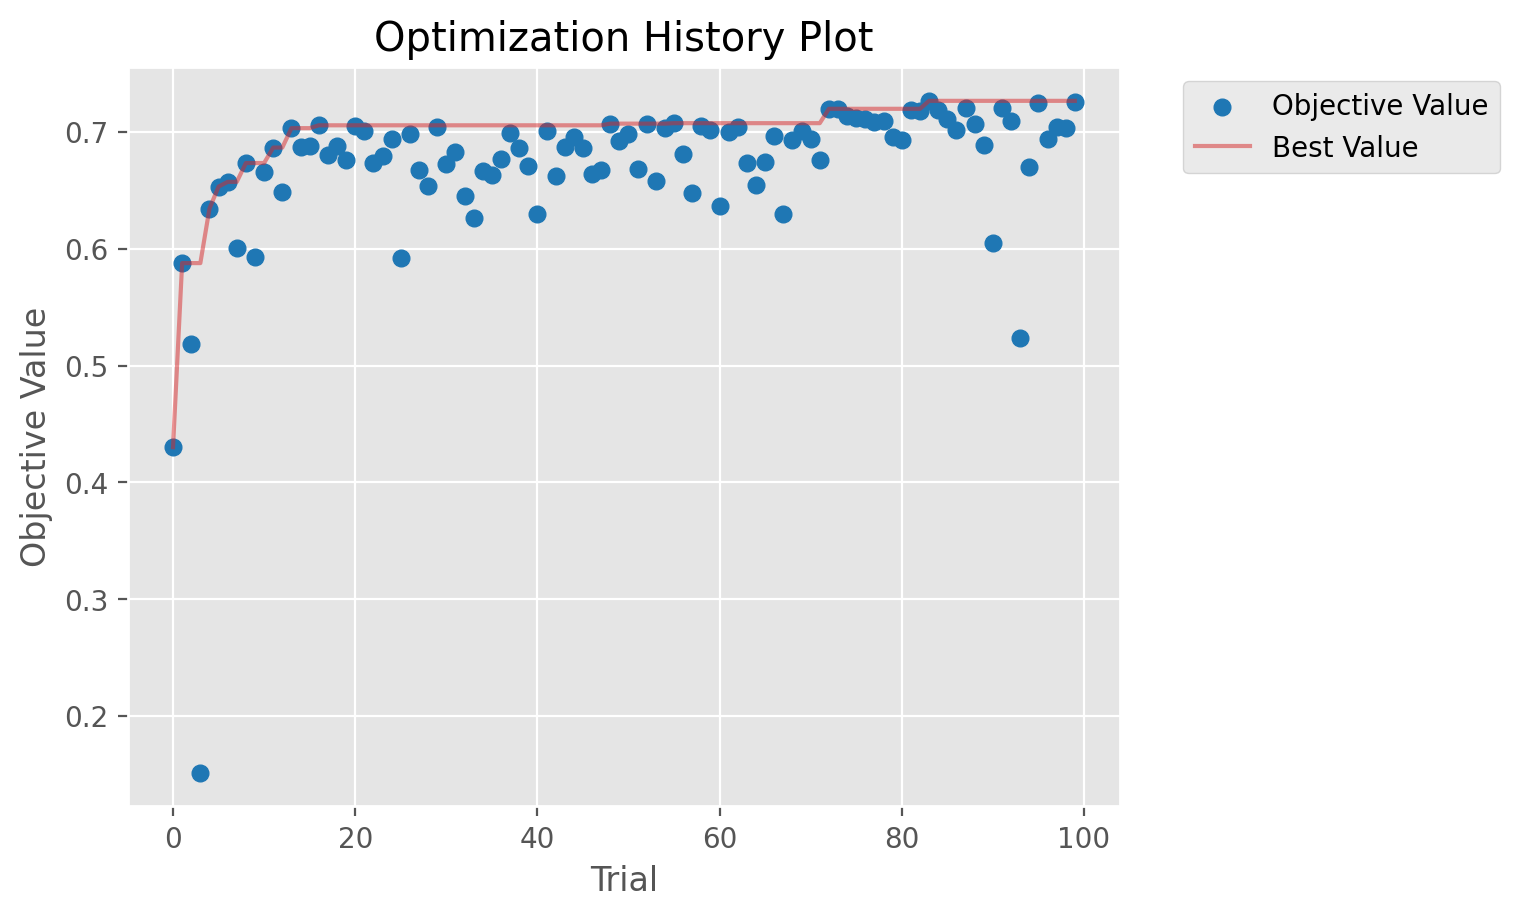

In [283]:
vis.plot_optimization_history(objeto_de_estudo_arvore)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

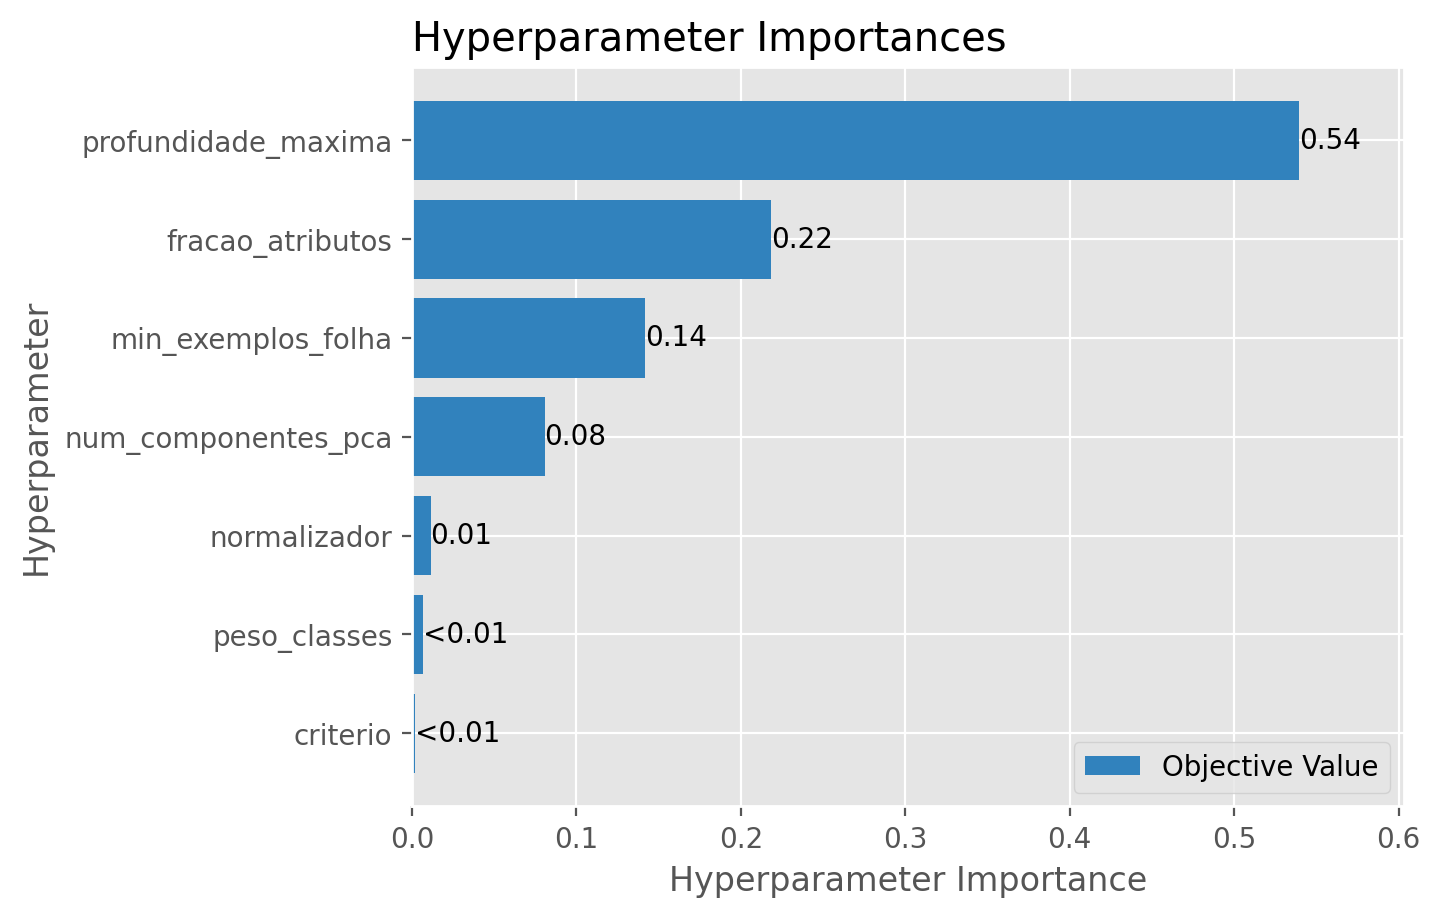

In [282]:
vis.plot_param_importances(objeto_de_estudo_arvore)

#### 3.6.5 Floresta Aleatória

In [175]:
def cria_instancia_floresta(trial):
    """Cria uma instância do modelo de floresta aleatória.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("num_arvores", 50, 300, log=True),
        "criterion": trial.suggest_categorical("criterio", ["gini", "entropy"]),
        "max_depth": trial.suggest_int("profundidade_maxima", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
        "max_features": trial.suggest_float("fracao_atributos", 0.1, 1),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        # argumentos fixos
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        RandomForestClassifier(**parametros),
    )

    return modelo

In [281]:
NOME_DO_ESTUDO = "floresta_codon_usage"

objeto_de_estudo_floresta = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
)

In [272]:
if len(objeto_de_estudo_floresta.trials) == 0:
    objeto_de_estudo_floresta.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "num_arvores": 100,
            "criterio": "gini",
            "min_exemplos_folha": 1,
            "peso_classes": None,
        }
    )

In [273]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_floresta,
)

if len(objeto_de_estudo_floresta.trials) < NUM_TENTATIVAS:
    objeto_de_estudo_floresta.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [179]:
melhor_trial_floresta = objeto_de_estudo_floresta.best_trial

print(f"Número do melhor trial: {melhor_trial_floresta.number}")
print(f"F1 macro do melhor trial: {melhor_trial_floresta.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_floresta.params}")

Número do melhor trial: 94
F1 macro do melhor trial: 85.6%
Parâmetros do melhor trial: {'num_arvores': 185, 'criterio': 'gini', 'profundidade_maxima': 29, 'min_exemplos_folha': 3, 'fracao_atributos': 0.13353796668701887, 'peso_classes': 'balanced', 'normalizador': 'max_abs', 'num_componentes_pca': 41}


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

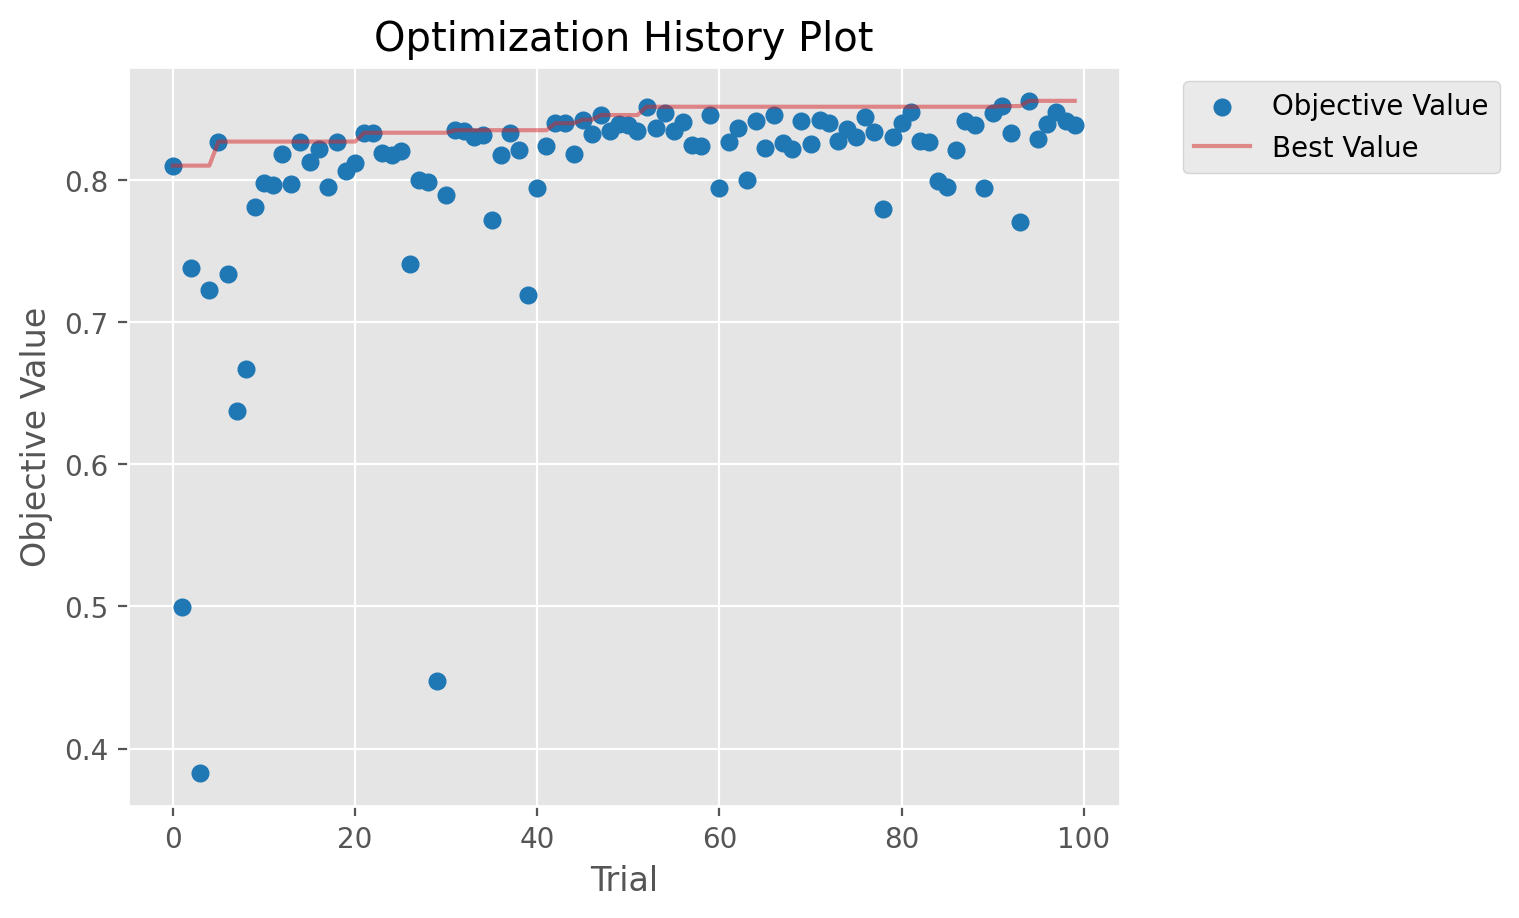

In [280]:
vis.plot_optimization_history(objeto_de_estudo_floresta)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

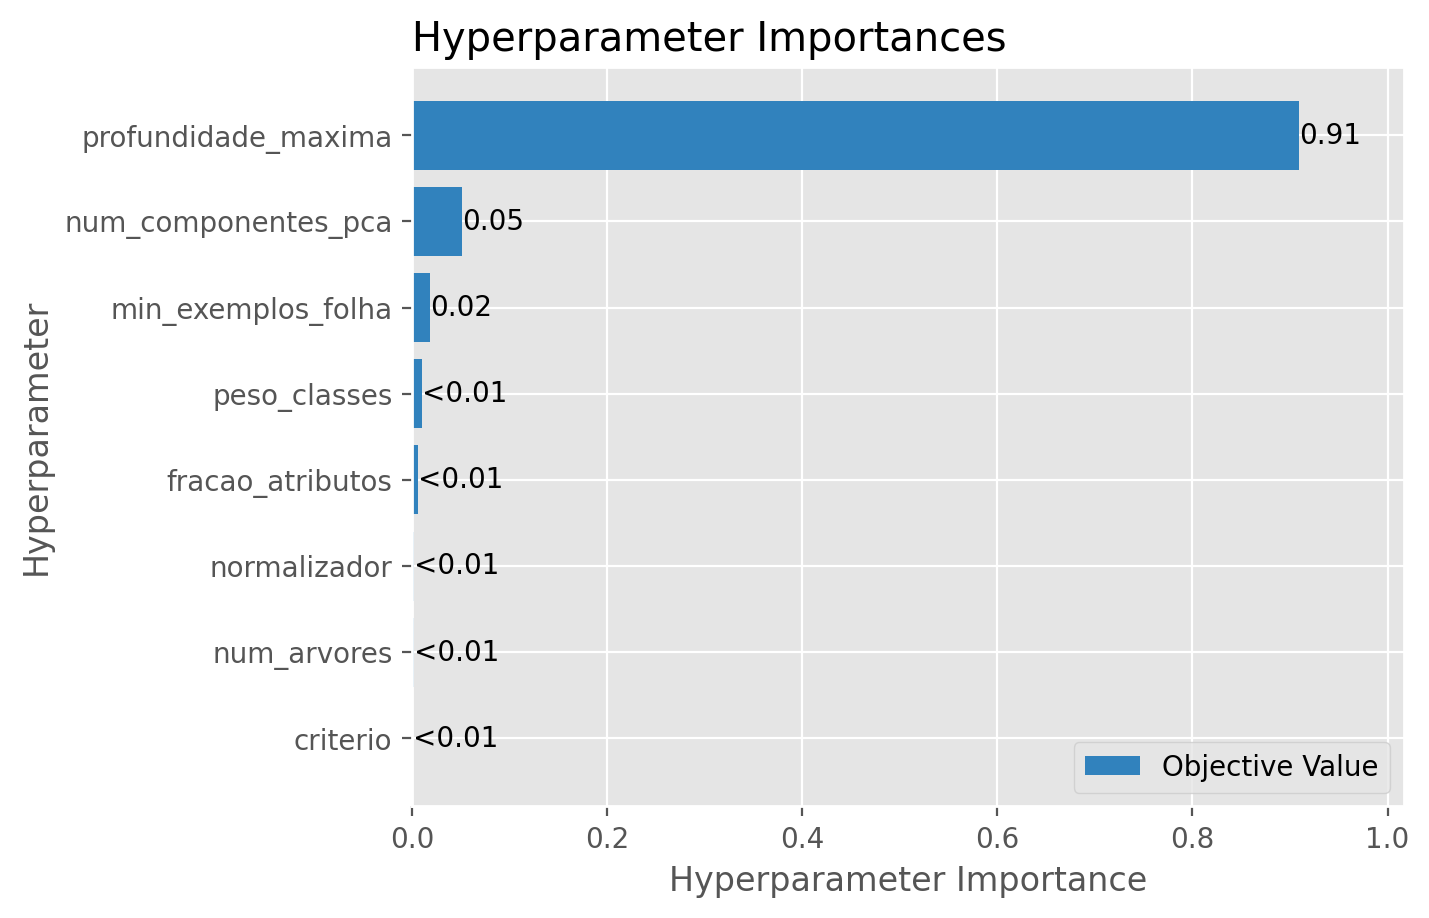

In [279]:
vis.plot_param_importances(objeto_de_estudo_floresta)

#### 3.6.6 Gradient Boosting (HistGradientBoosting)

In [182]:
def cria_instancia_hgb(trial):
    """Cria uma instância do modelo HistGradientBoosting.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "learning_rate": trial.suggest_float("taxa_aprendizado", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("num_iteracoes", 50, 500, log=True),
        "max_leaf_nodes": trial.suggest_int("max_folhas", 8, 128, log=True),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 5, 100, log=True),
        "l2_regularization": trial.suggest_float("regularizacao_l2", 1e-6, 10, log=True),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        # argumentos fixos
        "early_stopping": False,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        HistGradientBoostingClassifier(**parametros),
    )

    return modelo

In [276]:
NOME_DO_ESTUDO = "hgb_codon_usage"

objeto_de_estudo_hgb = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
)

In [274]:
if len(objeto_de_estudo_hgb.trials) == 0:
    objeto_de_estudo_hgb.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "taxa_aprendizado": 0.1,
            "num_iteracoes": 100,
            "max_folhas": 31,
            "min_exemplos_folha": 20,
            "peso_classes": None,
        }
    )

In [275]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_hgb,
)

if len(objeto_de_estudo_hgb.trials) < NUM_TENTATIVAS:
    objeto_de_estudo_hgb.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [186]:
melhor_trial_hgb = objeto_de_estudo_hgb.best_trial

print(f"Número do melhor trial: {melhor_trial_hgb.number}")
print(f"F1 macro do melhor trial: {melhor_trial_hgb.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_hgb.params}")

Número do melhor trial: 56
F1 macro do melhor trial: 90.5%
Parâmetros do melhor trial: {'taxa_aprendizado': 0.15396809661073957, 'num_iteracoes': 394, 'max_folhas': 25, 'min_exemplos_folha': 50, 'regularizacao_l2': 0.0031178452130927676, 'peso_classes': 'balanced', 'normalizador': 'max_abs', 'num_componentes_pca': 64}


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

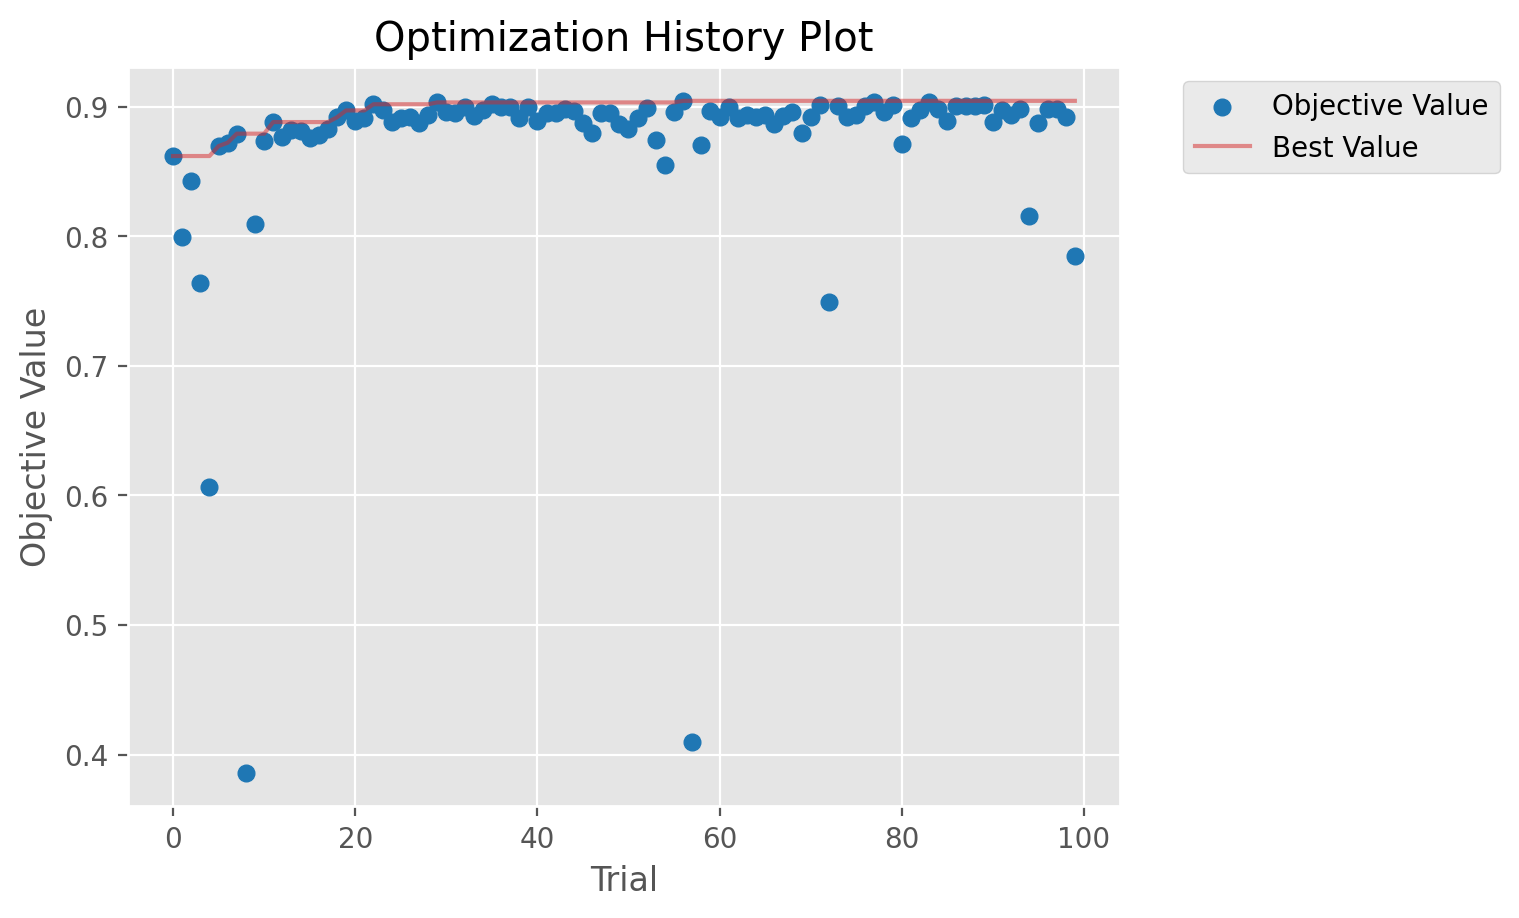

In [277]:
vis.plot_optimization_history(objeto_de_estudo_hgb)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

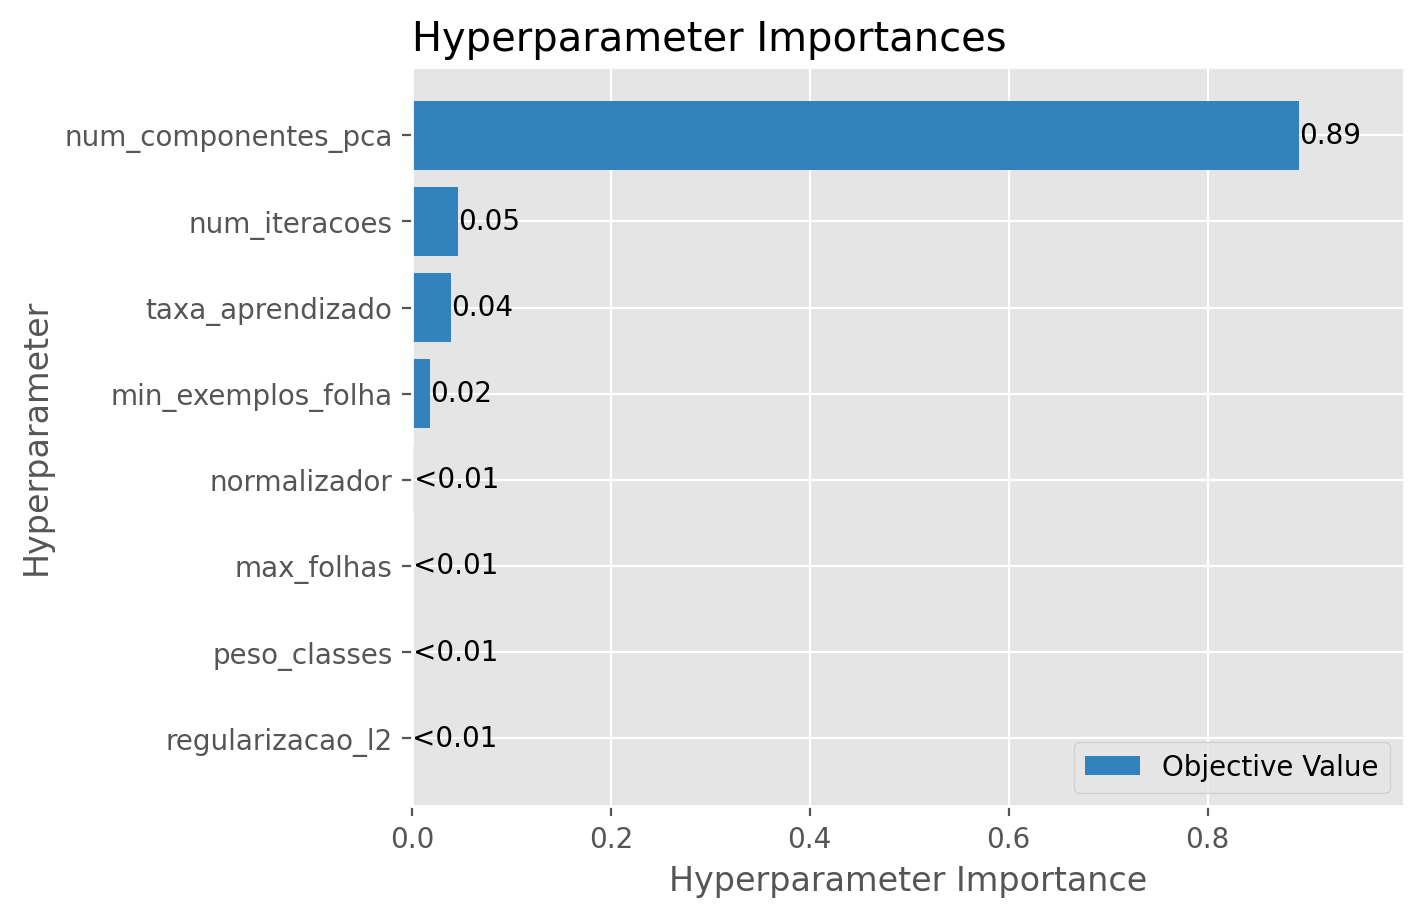

In [278]:
vis.plot_param_importances(objeto_de_estudo_hgb)

#### 3.6.7 Resumo da Otimização 

$ \ \ \ \ \ $ A tabela a seguir resume a otimização realizada para cada algoritmo. Todos os estudos testaram pelo menos 100 conjuntos distintos de hiperparâmetros, cada um avaliado por validação cruzada com 5 folds, o que corresponde a pelo menos 500 modelos treinados por algoritmo. 

In [255]:
estudos = {
    "Regressão logística": objeto_de_estudo_reglog,
    "k-NN": objeto_de_estudo_knn,
    "Árvore de decisão": objeto_de_estudo_arvore,
    "Floresta aleatória": objeto_de_estudo_floresta,
    "HistGradientBoosting": objeto_de_estudo_hgb,
}

linhas = []
for nome, estudo in estudos.items():
    df_tentativas = estudo.trials_dataframe()
    df_concluidas = df_tentativas[df_tentativas["state"] == "COMPLETE"]

    colunas_hiperparametros = [c for c in df_concluidas.columns if c.startswith("params_")]
    conjuntos_distintos = len(df_concluidas[colunas_hiperparametros].drop_duplicates())

    tentativa_padrao = estudo.trials[0]
    f1_padrao = tentativa_padrao.value * 100 if tentativa_padrao.value is not None else np.nan

    linhas.append({
        "Modelo": nome,
        "Tentativas concluídas": len(df_concluidas),
        "Conjuntos distintos de hiperparâmetros": conjuntos_distintos,
        "Hiperparâmetros otimizados": len(colunas_hiperparametros),
        "Folds por tentativa": NUM_FOLDS,
        "Modelos treinados": len(df_concluidas) * NUM_FOLDS,
        "F1 macro padrão (%)": round(f1_padrao, 1),
        "Melhor F1 macro (%)": round(estudo.best_value * 100, 1),
    })

resumo_optuna = pd.DataFrame(linhas).set_index("Modelo")
resumo_optuna

,Tentativas concluídas,Conjuntos distintos de hiperparâmetros,Hiperparâmetros otimizados,Folds por tentativa,Modelos treinados,F1 macro padrão (%),Melhor F1 macro (%)
Modelo,,,,,,,
Regressão logística,200,199,4,5,1000,85.0,85.7
k-NN,125,124,5,5,625,88.3,90.8
Árvore de decisão,100,100,7,5,500,43.0,72.7
Floresta aleatória,100,100,8,5,500,81.0,85.6
HistGradientBoosting,100,100,8,5,500,86.2,90.5


$ \ \ \ \ \ $ Em todos os casos, a otimização superou o desempenho obtido na primeira tentativa de cada estudo. Para a regressão logística, o k-NN e o HistGradientBoosting, essa tentativa utilizou os hiperparâmetros padrão do scikit-learn, e os ganhos foram de 0,7, 2,5 e 4,3 pontos percentuais, respectivamente. Para a árvore de decisão e a floresta aleatória, alguns hiperparâmetros padrão não estavam contidos no espaço de busca (como a profundidade máxima, que por padrão é ilimitada) e foram sorteados pelo optuna na primeira tentativa, de modo que a comparação com o padrão é apenas aproximada. Ainda assim, o maior ganho foi observado na árvore de decisão, cujo F1 macro passou de 43,0% para 72,7%, indicando que esse algoritmo é o mais sensível à escolha dos hiperparâmetros.

<a id="val"></a>
### 3.7 Comparação dos Modelos por Validação Cruzada

$ \ \ \ \ \ $ Nesta seção, o melhor pipeline de cada algoritmo, com os hiperparâmetros encontrados pelo Optuna, será avaliado novamente por validação cruzada no conjunto de treino, utilizando os mesmos 5 folds da otimização. Com isso, obtemos o F1 macro de cada fold, o que permite comparar não só o desempenho médio dos modelos, mas também a sua variação entre os folds, e incluir o baseline na comparação. No caso, somo os folds são os mesmos, as médias coincidem com os melhores valores encontrados em cada estudo.

In [256]:
melhores_modelos = {
    "Regressão logística": cria_instancia_reglog(melhor_trial_reglog),
    "k-NN": cria_instancia_knn(melhor_trial_knn),
    "Árvore de decisão": cria_instancia_arvore(melhor_trial_arvore),
    "Floresta aleatória": cria_instancia_floresta(melhor_trial_floresta),
    "HistGradientBoosting": cria_instancia_hgb(melhor_trial_hgb),
}

resultados_cv = {"Baseline": f1_baseline}

for nome, modelo in melhores_modelos.items():
    resultados_cv[nome] = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        scoring=METRICA,
        cv=NUM_FOLDS,
    )

df_resultados_cv = pd.DataFrame(resultados_cv) * 100

resumo_cv = df_resultados_cv.agg(["mean", "std"]).T.round(1)
resumo_cv.columns = ["F1 macro médio (%)", "Desvio padrão (%)"]
resumo_cv.sort_values("F1 macro médio (%)", ascending=False)

,F1 macro médio (%),Desvio padrão (%)
k-NN,90.8,1.3
HistGradientBoosting,90.5,1.4
Regressão logística,85.7,1.2
Floresta aleatória,85.6,2.5
Árvore de decisão,72.7,2.8
Baseline,8.3,0.0


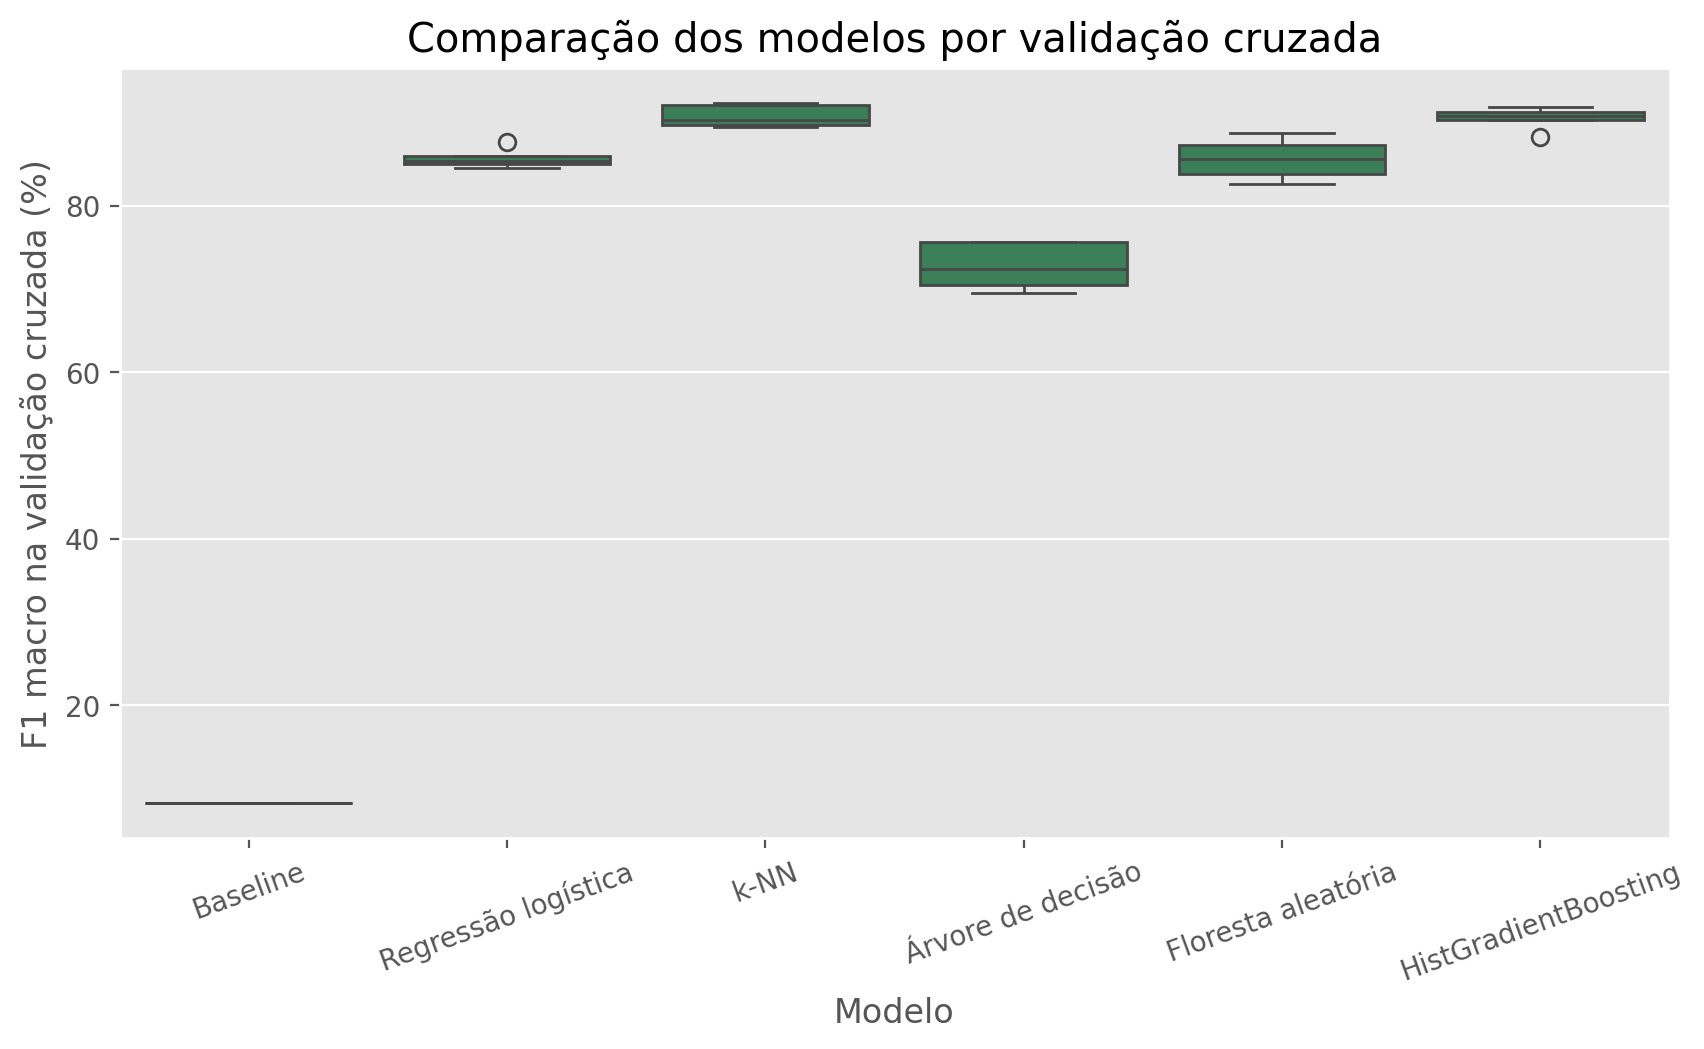

In [257]:
figura, eixo = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_resultados_cv, color="seagreen", ax=eixo)
eixo.set(
    xlabel="Modelo",
    ylabel="F1 macro na validação cruzada (%)",
    title="Comparação dos modelos por validação cruzada",
)
plt.xticks(rotation=20);

$ \ \ \ \ \ $ Todos os modelos superaram amplamente o baseline (8,3%). O k-NN (90,8% ± 1,3%) e o gradient boosting (90,5% ± 1,4%) obtiveram os maiores valores de F1 macro, seguidos pela regressão logística (85,7% ± 1,2%) e pela floresta aleatória (85,6% ± 2,5%). A árvore de decisão teve o menor desempenho (72,7%) e a maior variação entre os folds (2,8%), o que é coerente com a alta variância esperada para uma única árvore.

$ \ \ \ \ \ $ A diferença entre o k-NN e o gradient boosting (0,3 ponto percentual) é bem menor que o desvio padrão de cada um entre os folds, de modo que os dois modelos podem ser considerados equivalentes. Seguindo o critério definido na metodologia, o modelo com maior F1 macro médio, o k-NN, foi escolhido para a avaliação final. Essa escolha também trás a vantagem da simplicidade, pois o k-NN com um único vizinho é um modelo muito mais fácil de interpretar do que um comitê de quase 400 árvores.

<a id="teste"></a>
### 3.8 Avaliação Final no Conjunto de Teste

$ \ \ \ \ \ $ O modelo escolhido foi treinado com todo o conjunto de treino e avaliado uma única vez no conjunto de teste, que não foi utilizado em nenhuma etapa anterior. Esse resultado é a medida final do desempenho do modelo em dados nunca vistos.

In [258]:
nome_melhor = df_resultados_cv.drop(columns="Baseline").mean().idxmax()
print("Modelo escolhido:", nome_melhor)

modelo = melhores_modelos[nome_melhor]
modelo.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo.predict(X_teste)

F1_MACRO = f1_score(y_verdadeiro, y_previsao, average="macro")
ACURACIA = accuracy_score(y_verdadeiro, y_previsao)

print(f"F1 macro no teste: {F1_MACRO * 100:.1f}%")
print(f"Acurácia no teste: {ACURACIA * 100:.1f}%")

Modelo escolhido: k-NN
F1 macro no teste: 91.9%
Acurácia no teste: 93.9%


$ \ \ \ \ \ $ No conjunto de teste, o k-NN obteve F1 macro de 91,9% e acurácia de 93,9%. O F1 macro no teste é compatível com a estimativa da validação cruzada (90,8% ± 1,3%), ficando a menos de um desvio padrão de distância. Isso indica que o modelo não sofreu sobreajuste aos dados de treino e que a estimativa obtida por validação cruzada era confiável. Em relação ao baseline (8,3% de F1 macro e 32,9% de acurácia), o ganho é considerável.

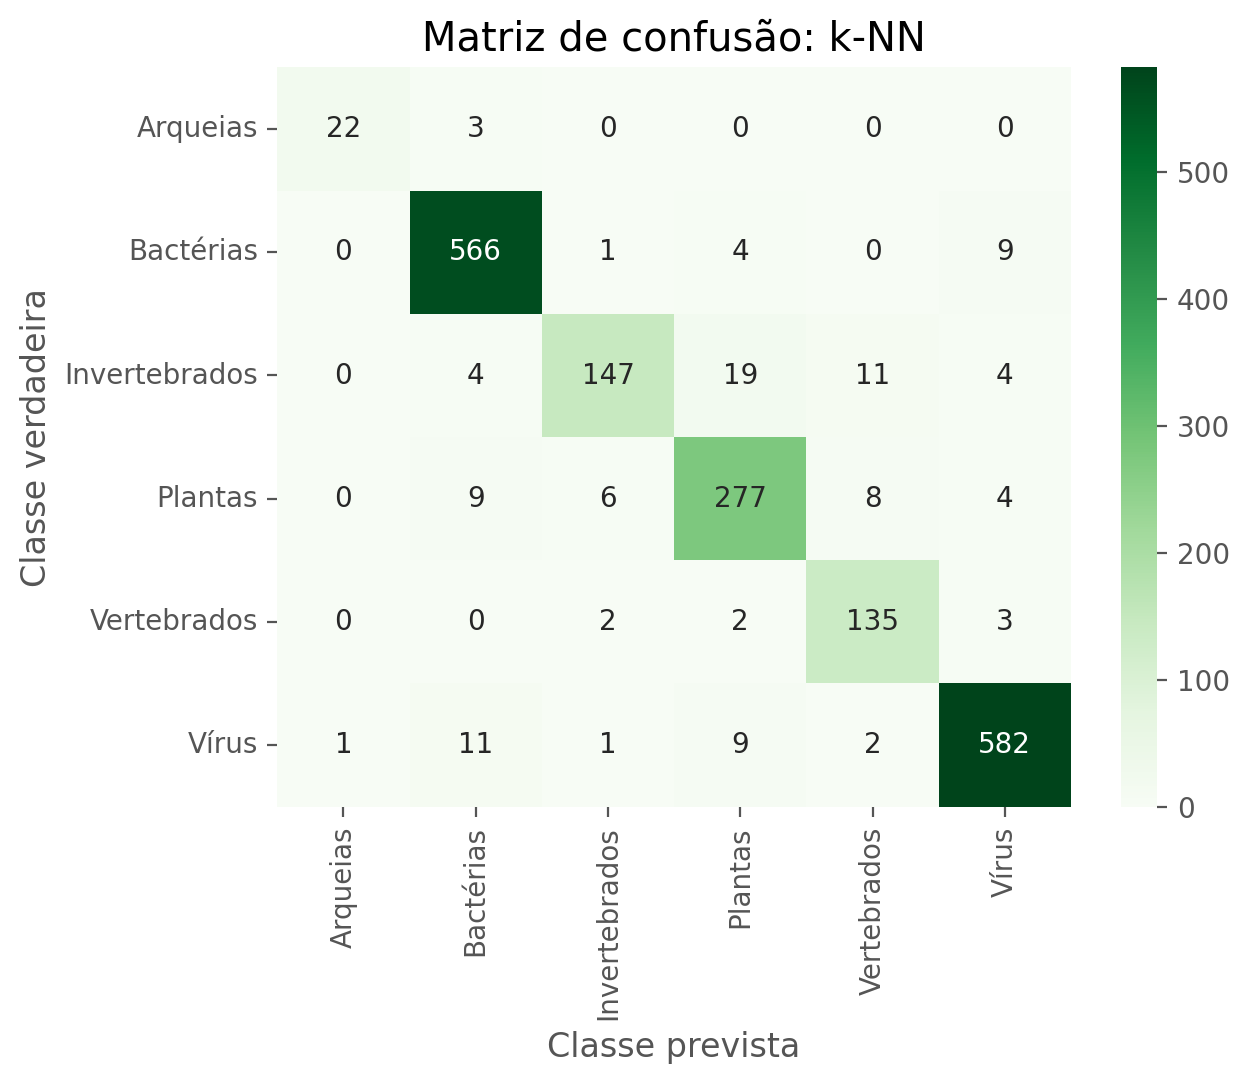

In [259]:
ordem_labels = sorted(df["Grupo"].unique())

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

eixo = sns.heatmap(df_conf, annot=True, fmt="d", cmap="Greens")
eixo.set(xlabel="Classe prevista", ylabel="Classe verdadeira", title=f"Matriz de confusão: {nome_melhor}");

$ \ \ \ \ \ $ Na matriz de confusão, a diagonal corresponde aos acertos. O modelo identificou corretamente cerca de 98% das bactérias (566 de 580), 96% dos vírus (582 de 606), 95% dos vertebrados (135 de 142), 91% das plantas (277 de 304) e 88% das arqueias (22 de 25). Os invertebrados foram o grupo mais difícil, com 79% de acerto (147 de 185), sendo confundidos principalmente com plantas (19 casos) e vertebrados (11 casos). Uma explicação, bem possível, é que a categoria de invertebrados do GenBank é bastante heterogênea, reunindo organismos muito diferentes entre si.

$ \ \ \ \ \ $ Os erros fazem sentido do ponto de vista biológico. As três arqueias classificadas incorretamente foram confundidas com bactérias, o outro grupo de procariontes. Além disso, há confusões nos dois sentidos entre bactérias e vírus (9 bactérias classificadas como vírus e 11 vírus classificados como bactérias), o que é coerente com o fato de que muitos vírus, como os bacteriófagos, infectam bactérias e tendem a adaptar seu uso de códons ao do hospedeiro

$ \ \ \ \ \ $ Para comparação do desempenho, a matriz de confusão do baseline no mesmo conjunto de teste:

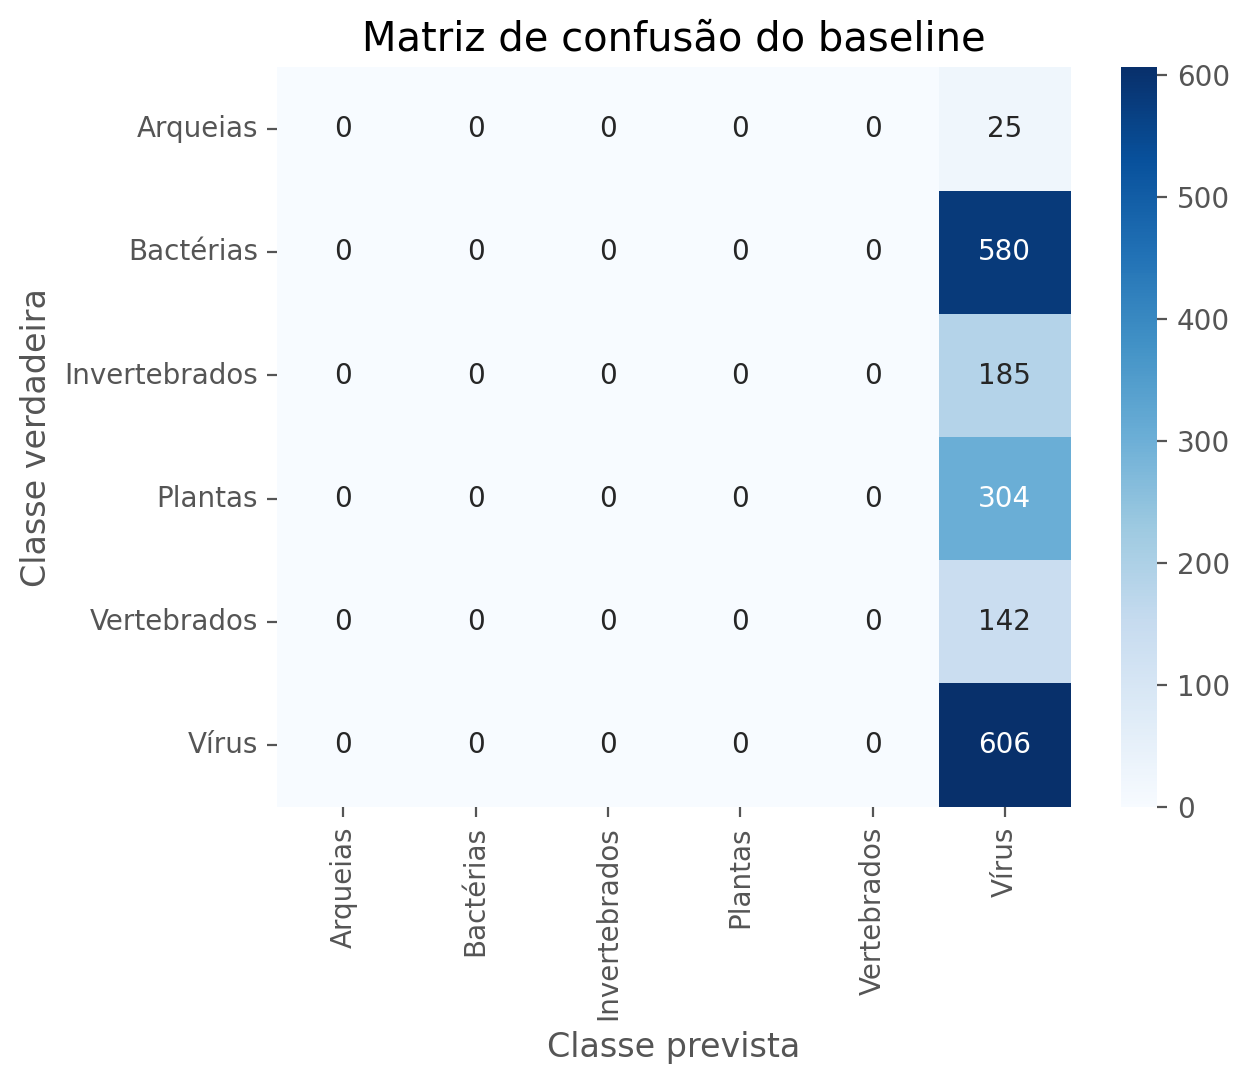

In [260]:
ordem_labels = sorted(df["Grupo"].unique())

modelo_baseline.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo_baseline.predict(X_teste)

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

eixo = sns.heatmap(df_conf, annot=True, fmt="d", cmap="Blues")
eixo.set(xlabel="Classe prevista", ylabel="Classe verdadeira", title="Matriz de confusão do baseline");

$ \ \ \ \ \ $ A comparação entre as duas matrizes evidencia o ganho obtido, uma vez que enquanto o baseline classifica todos os organismos como vírus, o k-NN concentra quase todas as previsões na diagonal, acertando a maior parte dos organismos de todos os grupos.

<a id="interp"></a>
### 3.9 Interpretação dos Resultados

$ \ \ \ \ \ $ Agora podemos investigar com mais detalhes o desempenho do modelo escolhido em cada grupo e quais atributos mais influenciam suas previsões, discutindo os resultados à luz da biologia e da literatura.

#### 3.9.1 Desempenho por Grupo Taxonômico

In [290]:
y_previsao_teste = modelo.predict(X_teste)

relatorio = classification_report(y_teste, y_previsao_teste, output_dict=True, zero_division=0)
df_relatorio = pd.DataFrame(relatorio).T.loc[ordem_labels, ["precision", "recall", "f1-score"]] * 100
df_relatorio.columns = ["Precisão", "Sensibilidade", "F1"]
df_relatorio.round(1)

,Precisão,Sensibilidade,F1
Arqueias,95.7,88.0,91.7
Bactérias,95.4,97.6,96.5
Invertebrados,93.6,79.5,86.0
Plantas,89.1,91.1,90.1
Vertebrados,86.5,95.1,90.6
Vírus,96.7,96.0,96.4


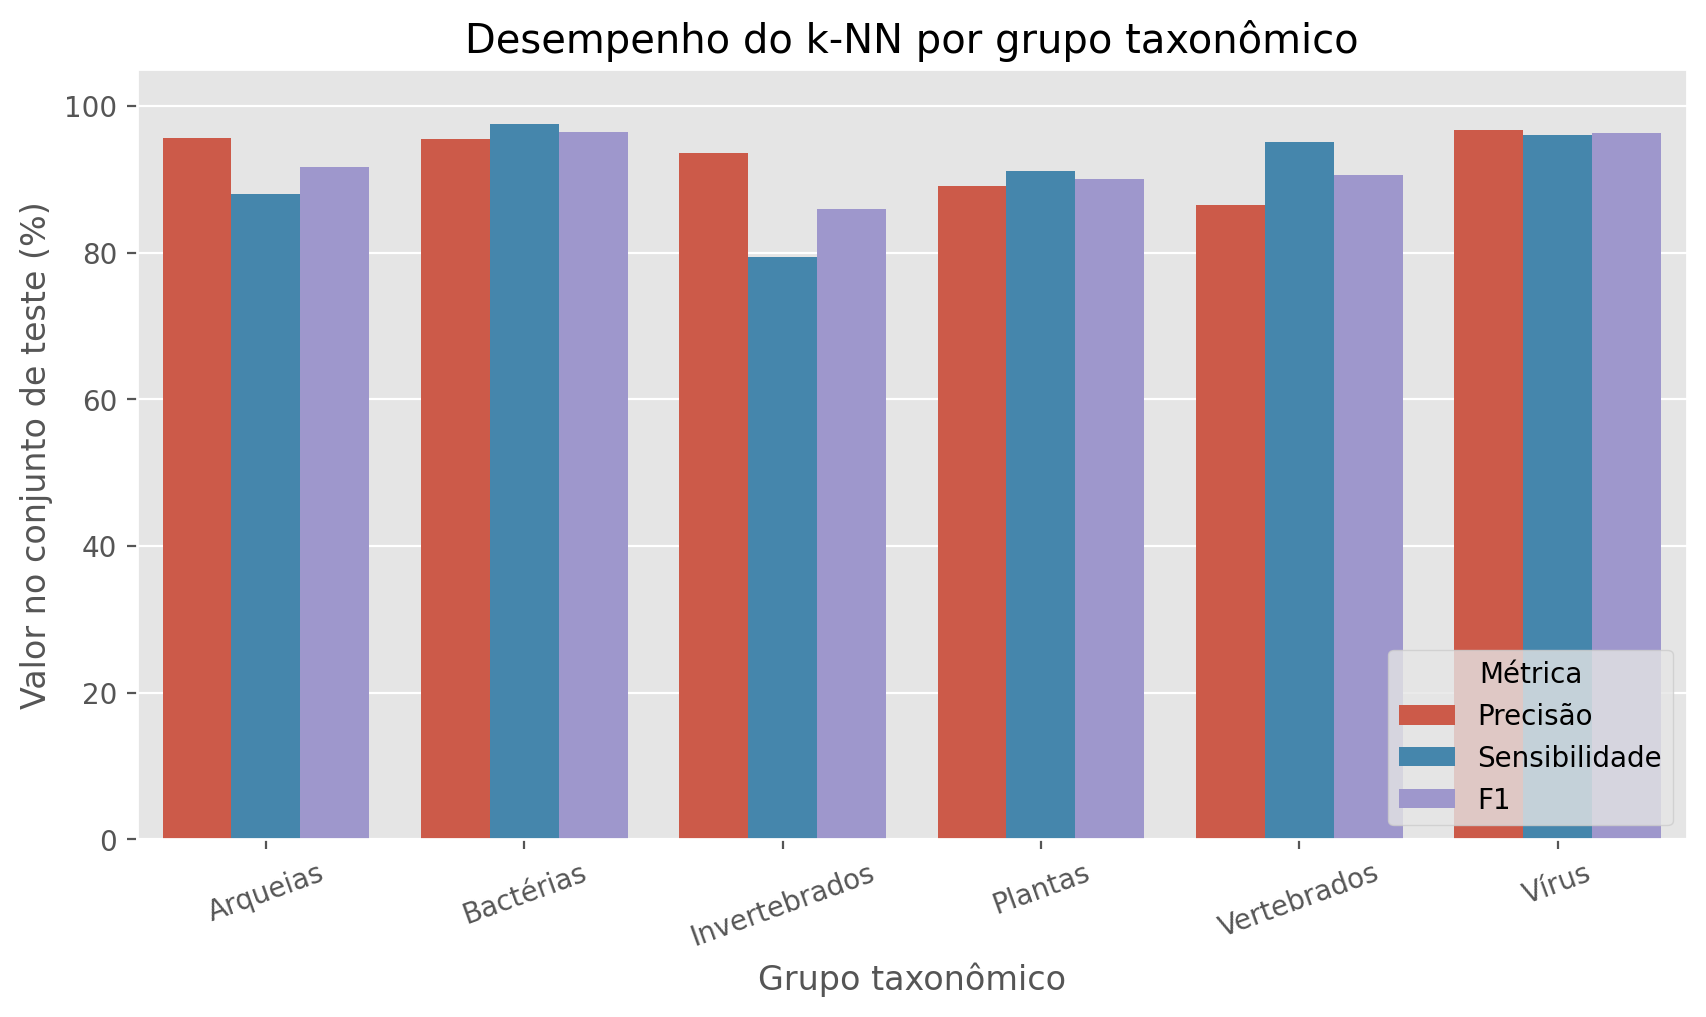

In [291]:
dados_metricas = df_relatorio.reset_index(names="Grupo").melt(
    id_vars="Grupo", var_name="Métrica", value_name="Valor (%)"
)

figura, eixo = plt.subplots(figsize=(10, 5))
sns.barplot(data=dados_metricas, x="Grupo", y="Valor (%)", hue="Métrica", ax=eixo)
eixo.set(
    xlabel="Grupo taxonômico",
    ylabel="Valor no conjunto de teste (%)",
    title=f"Desempenho do {nome_melhor} por grupo taxonômico",
)
eixo.set_ylim(0, 105)
eixo.legend(title="Métrica", loc="lower right")
plt.xticks(rotation=20);

#### 3.9.2 Importância dos Atributos

#### 3.9.3 Discussão

<a id="conclusao"></a>
## 4. Conclusões e Principais Aprendizados

$ \ \ \ \ \ $ Este trabalho investigou se é possível identificar o grupo taxonômico de um organismo a partir do seu viés de uso de códons. Após a limpeza dos dados e a reorganização das categorias em seis grupos, foram comparados cinco algoritmos de aprendizado de máquina, com hiperparâmetros otimizados pelo Optuna. Todos superaram amplamente o baseline, e o melhor modelo, o k-NN com um único vizinho, alcançou F1 macro de 91,9% e acurácia de 93,9% no conjunto de teste. Assim, a resposta à pergunta do trabalho é positiva: o uso de códons carrega informação suficiente para distinguir, com alto desempenho, arqueias, bactérias, vírus, plantas, invertebrados e vertebrados. Os erros mais frequentes ocorreram entre grupos biologicamente relacionados, como arqueias e bactérias, bactérias e vírus, e entre os invertebrados e os demais eucariontes.

$ \ \ \ \ \ $ Como trabalhos futuros, seria interessante avaliar o desempenho com uma divisão dos dados agrupada por gênero ou família taxonômica, para medir a capacidade de classificar organismos sem parentes próximos no treino; utilizar a validação cruzada aninhada, para estimar o desempenho de forma ainda mais rigorosa; e testar atributos com significado biológico, como o conteúdo de GC na terceira posição dos códons ou o uso relativo de códons sinônimos.

<a id="interacao"></a>
## 5. Descrisão do uso de IA neste trabalho

$ \ \ \ \ \ $ Ao longo do desenvolvimento deste trabalho, foi utilizada a ferramenta de Inteligência Artificial Claude [[13]](#refs) como apoio em diferentes etapas do processo, como na depuração de código (debug), em que a IA foi utilizada para identificar a causa de diversos erros e avisos (warnings) encontrados durante a execução do notebook. Entre os principais casos, que fui sempre anotando, podemos citar: 
- **Erro no k-NN com classes em texto:** durante a otimização do *k*-NN, diversas tentativas do Optuna falharam com a mensagem `ValueError: invalid literal for int() with base 10: 'Arqueias'`. Com o auxílio da IA, identifiquei que todas as tentativas com falha utilizavam pesos uniformes (`weights="uniform"`). Nesse caso, o scikit-learn utiliza um método interno de cálculo que tenta converter os nomes das classes em números inteiros, o que não é possível quando o *target* é representado por texto. A solução foi fixar o argumento `algorithm="ball_tree"`, que altera apenas a forma como os vizinhos mais próximos são encontrados, sem modificar o resultado do modelo. Como as tentativas com falha ficaram registradas no estudo, o arquivo `.db` do *k*-NN foi apagado e a otimização foi refeita.
- **Colunas de códons lidas como texto:** duas colunas de frequência (`UUU` e `UUC`) foram lidas como texto pelo `pandas`, pois continham valores mal formatados. A IA sugeriu a conversão com `pd.to_numeric(errors="coerce")`, que transformou esses valores em ausentes, permitindo identificar e remover as duas linhas problemáticas.
- **Modelo não treinado (`NotFittedError`):** ao tentar gerar a matriz de confusão do *baseline*, o modelo não havia sido treinado, pois a função `cross_val_score` treina apenas cópias do modelo durante a validação cruzada. A solução foi treinar o modelo com `fit` antes de realizar as previsões.
- **Número de tentativas maior que o esperado:** o estudo da regressão logística apresentou um melhor *trial* de número 123, indicando mais de 100 tentativas. A IA explicou que, como o estudo é salvo em arquivo com `load_if_exists=True`, cada nova execução da célula de otimização acrescentava tentativas ao estudo existente. O arquivo foi apagado e a otimização refeita uma única vez.
- **Gráficos do Optuna não exibidos:** os gráficos interativos do `optuna.visualization` não apareciam no VS Code. A solução foi utilizar a versão em `matplotlib` desses gráficos (`optuna.visualization.matplotlib`), que também é exibida corretamente no GitHub.

<a id="agradecimentos"></a>
## 6. Agradecimentos

$ \ \ \ \ \ $ Agradeço aos estudantes da Ilum Glauber Nascimento de Oliveira e Gabriela Oliveira de Lima Cabral pelas trocas e discussões ao longo do desenvolvimento deste trabalho, que contribuiram para sua concretização.

<a id="refs"></a>
## 7. Referências

[1] PARVATHY, Sujatha Thankeswaran; UDAYASURIYAN, Varatharajalu; BHADANA, Vijaipal. Codon usage bias. Molecular Biology Reports, v. 49, n. 1, p. 539-565, 2022. DOI: 10.1007/s11033-021-06749-4. Disponível em: https://pmc.ncbi.nlm.nih.gov/articles/PMC8613526/. Acesso em: 21 set. 2026. <br>
[2] HALLEE, L.; KHOMTCHOUK, B. B. Codon usage [Dataset]. UCI Machine Learning Repository, 2020. Disponível em: https://doi.org/10.24432/C5KP6B. Acesso em: 21 set. 2026. <br>
[3]

P.S. As referências estão ordenadas de acordo com a aparição no documento.